# Taller RL Trader 2 — DQN y A3C para trading con un único activo

**Objetivo.** Entrenar agentes de *Deep Reinforcement Learning* (DQN y A3C) que inviertan en el
entorno `SimpleTradingEnv` del enunciado, sobre los cuatro generadores de precios propuestos,
y compararlos de forma rigurosa con el agente aleatorio, *buy & hold* y el Q-learning tabular
del taller anterior (petición explícita del profesor en clase).

**Estructura del trabajo**

| Fichero | Contenido |
|---|---|
| `rl_trading/env.py` | Entorno y generadores **literales** del notebook + generación reproducible por semilla |
| `rl_trading/encoding.py` | Codificación del estado para la red (tendencia normalizada, posición) |
| `rl_trading/dqn.py` | DQN: replay, red objetivo, Double DQN, Huber, ε-decay |
| `rl_trading/a3c.py` | A3C asíncrono real (multiproceso, Hogwild, `SharedAdam`, n-step, entropía) |
| `rl_trading/qlearning.py` | Q-learning tabular (referencia del taller de Luis) |
| `rl_trading/baselines.py` | Aleatorio, B&H, momentum, contraria, oráculo miope, oráculo con información oculta |
| `rl_trading/evaluate.py` | Simulador vectorizado (idéntico al entorno), métricas y tests pareados |
| `rl_trading/stats.py` | Regla única de veredicto, TOST, Holm/Benjamini-Hochberg, Friedman-Nemenyi, potencia |
| `experiments/*.py` | Ajuste, ejecución final, ablaciones, análisis, evaluación global (§11–§12) |
| `make_memoria.py`, `check_memoria.py` | Memoria de 2 páginas generada desde `results/` y sus comprobaciones de consistencia |
| `tests_sanity.py` | Verificación simulador ≡ entorno, B&H ≡ notebook |

Este notebook **no reentrena** (eso lo hacen los scripts de `experiments/`, en paralelo);
carga los resultados guardados en `results/` y los analiza. Todo es reproducible con semillas.

## 0. Análisis del enunciado y de las indicaciones del profesor

**Requisitos explícitos (notebook):**
1. Implementar al menos **DQN** y **A3C**, con al menos los **4 generadores** de precios.
2. Muchos episodios de entrenamiento, **cada uno con una serie nueva** del mismo generador.
3. Evaluar en **series de test nuevas** y **promediar** sobre varias.
4. Comparar con el **agente aleatorio** y **buy & hold**, razonando si la estrategia es la esperada.
5. Ajustar **α, ε (con decaimiento), γ y nº de episodios**.
6. **Tabla** comparativa por generador con rendimiento y **tiempo de convergencia**.

**Indicaciones del profesor en clase (transcripciones 30/10 y 31/10):**
- *"En el taller no tenéis que cambiar el entorno"* → el entorno se usa **sin modificar**; sí se
  permite cambiar cómo se codifica el estado como entrada de la red.
- *"Quiero que no discreticéis"* → DQN y A3C reciben la tendencia **continua**.
- Comparar con el **Q-learning** del taller de Luis: *"me esperaría que al menos lo superarais"*.
- Monitorizar la **ganancia G** por episodio (con media móvil, porque la serie cambia en cada
  episodio), no el MSE; y no confundir *"G sube"* con *"gano dinero"*.
- Escalar recompensas, usar Huber / red objetivo para estabilizar, **no fiarse de una sola ejecución**.
- A3C = actor-crítico con red de **dos cabezas** (actor softmax + crítico lineal), como su notebook.

**Rúbrica:** 50% mínimos; 10% pruebas más allá de los mínimos; 20% calidad de presentación;
10% justificación de decisiones; 10% análisis crítico.

In [1]:
import json, os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
sys.path.insert(0, os.getcwd())
from rl_trading.env import SimpleTradingEnv, make_series, make_set, GENERATORS, GEN_LABELS
from rl_trading.evaluate import simulate, metrics
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
GENS = ["ciclo", "gbm", "reversion", "regimenes"]

## 1. El problema como MDP y verificación del entorno

**Estado** $s_t=(x_t, p_t)$ con $x_t=\mathrm{clip}\big((P_t-\bar P_{t-5:t})/\bar P_{t-5:t},-1,1\big)$
(tendencia sobre 6 precios) y $p_t\in\{0,1\}$ (posición). **Acciones** $a\in\{0{:}\text{vender},1{:}\text{mantener},2{:}\text{comprar}\}$.
**Recompensa**
$$r_{t+1} = -c\,\mathbb 1[\text{opera}] + p_{t+1}\,\frac{P_{t+1}-P_t}{P_t},\qquad c=0.001 .$$

Observaciones importantes para el diseño (y la defensa):
- **La recompensa es aditiva en rendimientos aritméticos**, mientras que la riqueza es
  multiplicativa: $W_T = W_0\prod_t(1+p_t\rho_t)(1-c)^{n_\text{ops}}$. Maximizar $\sum r$ no es
  exactamente maximizar $\log W_T$ (diferencia $\approx \tfrac12\sum\rho_t^2$, *arrastre por volatilidad*).
  Por eso reportamos **ambas** métricas.
- La **comisión** hace que el valor de estar dentro dependa de la posición actual: crea una
  **banda de histéresis** (comprar exige más señal que mantener). Por eso la posición forma parte del estado.
- El entorno devuelve `terminated=True` en el último paso. **Decidimos** tratarlo como **límite de tiempo**
  (500 precios) y hacer *bootstrap* también en esa transición: la serie no termina por nada que el agente
  observe y el estado no contiene $t$, así que tratarlo como terminal introduce *aliasing* (Pardo et al., 2018).
  Es una decisión sobre el objetivo de aprendizaje, no una reproducción literal del entorno; por eso se
  contrasta en §12 (DQN con `timeout_bootstrap=False`, 3 semillas): no hay diferencias demostradas.
- El generador "ciclo" usa `np.linspace(0, 50, n_steps)`: su periodo depende de `n_steps` →
  fijamos **500** en entrenamiento y test. Su volatilidad por paso es del 10%, por lo que la riqueza
  final tiene colas enormes: usamos **medianas y log-riqueza**.

**Verificación.** Para evaluar miles de episodios rápidamente se implementó un simulador
vectorizado. Antes de usarlo se comprueba que reproduce **exactamente** el entorno original
con acciones aleatorias y que el B&H coincide con el del notebook:

In [2]:
import tests_sanity; tests_sanity.main()

OK. Máxima discrepancia simulador vs entorno: 0.0


## 2. ¿Qué estrategia cabe esperar en cada mercado? (análisis previo de predictibilidad)

Antes de entrenar, medimos con 400 series de **entrenamiento** el rendimiento medio del paso
siguiente condicionado al decil de la tendencia observada. Esto da la **estrategia de referencia**
contra la que juzgar si lo aprendido "es lo esperado" (ejercicio 2).

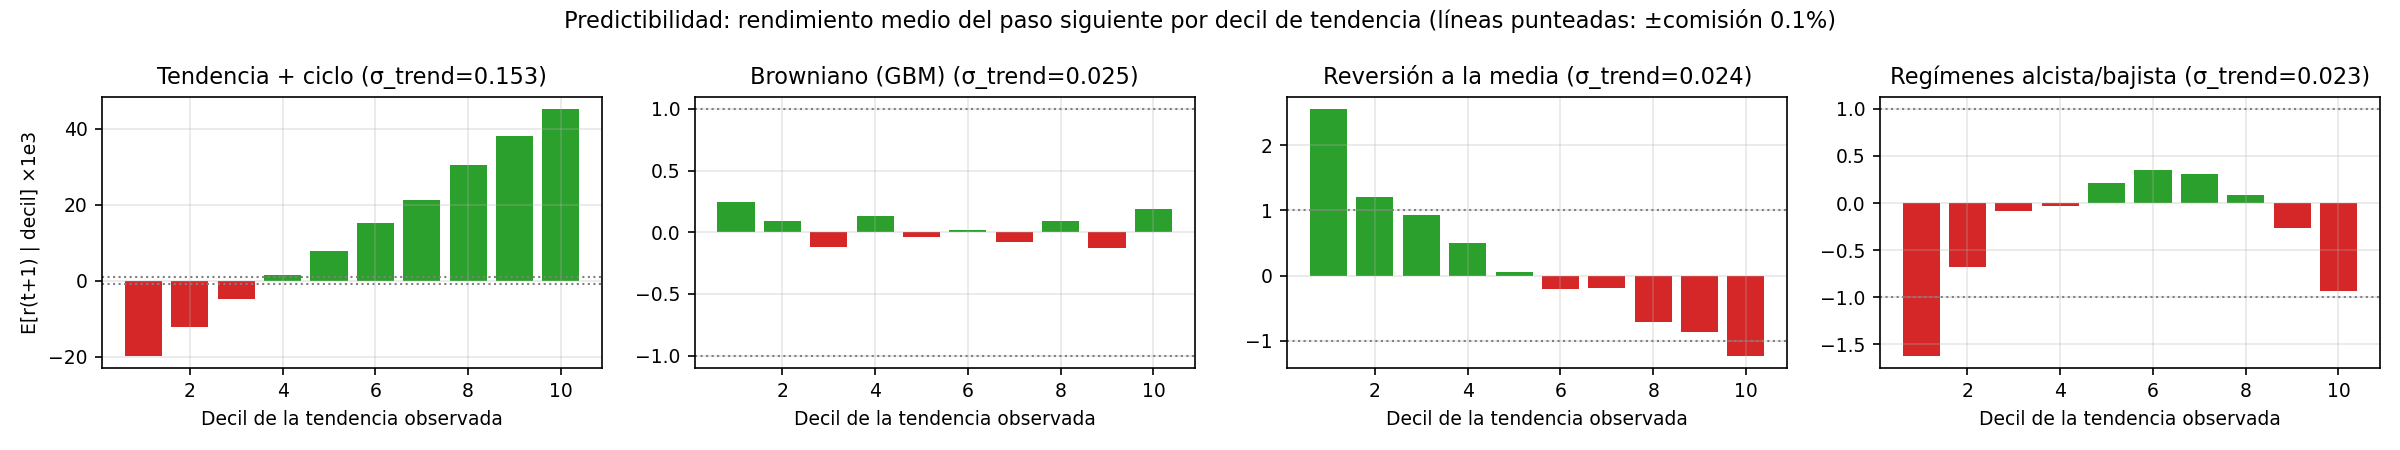

In [3]:
display(Image("results/figures/predictability.png"))

| Generador | Estructura | Estrategia esperada |
|---|---|---|
| Tendencia + ciclo | Fuerte **momentum** (el ciclo de periodo ≈63 pasos domina la tendencia; $E[r]$ de −20‰ a +45‰) | Estar dentro si la tendencia es positiva (o poco negativa); batir a B&H con mucho margen |
| GBM | **Sin predictibilidad** (rendimientos i.i.d.; $\rho\approx0$) | Ninguna regla bate a B&H en esperanza; lo racional es **no sobreoperar** (B&H o casi) |
| Reversión a la media | **Contraria**: tras subir, baja ($E[r]$ de +2.4‰ a −1.2‰) | Comprar con tendencia negativa, vender con positiva |
| Regímenes | **No monótona** (U invertida): tendencias extremas delatan el régimen bajista, más volátil | Estar dentro solo con tendencia moderada; el beneficio esperado es pequeño frente a la comisión → mucho tiempo fuera |

El caso de regímenes es especialmente interesante: una regla lineal de umbral (momentum o
contraria) **no puede** representar la política óptima; una red neuronal sí.

## 3. Fundamentos teóricos de los algoritmos

### 3.1 Q-learning tabular (referencia)
Ecuación de optimalidad de Bellman: $Q^*(s,a)=\mathbb E\big[r+\gamma\max_{a'}Q^*(s',a')\big]$.
Actualización: $Q(s,a)\leftarrow Q(s,a)+\alpha\big[r+\gamma\max_{a'}Q(s',a')-Q(s,a)\big]$.
Converge a $Q^*$ con exploración suficiente y $\alpha$ decreciente (Watkins & Dayan, 1992).
Requiere **discretizar** la tendencia (aquí, bins equiprobables de la tendencia normalizada).

### 3.2 DQN (Mnih et al., 2015)
Se sustituye la tabla por una red $Q_\theta(s,\cdot)$ (2 entradas → 64 → 64 → 3 salidas lineales,
una por acción) y se minimiza
$$\mathcal L(\theta)=\mathbb E_{(s,a,r,s')\sim\mathcal D}\Big[\ell_\delta\big(y-Q_\theta(s,a)\big)\Big],\quad
y=r+\gamma\,Q_{\bar\theta}\big(s',\arg\max_{a'}Q_\theta(s',a')\big).$$
- **Experience replay** $\mathcal D$: rompe la correlación temporal de transiciones consecutivas
  (muy fuerte en series de precios) y reutiliza datos.
- **Red objetivo** $\bar\theta$ (copia cada $C$ pasos): el *target* deja de moverse con cada
  actualización (el "target dinámico" del que habló el profesor).
- **Double DQN** (van Hasselt et al., 2016): desacopla selección y evaluación de $a'$ y reduce
  el sesgo de sobreestimación de $\max$ — relevante aquí porque las recompensas son muy ruidosas.
- **Huber** $\ell_\delta$ y recorte de gradiente: robustez ante rendimientos extremos (ciclo: ±30%).
- **ε-greedy con decaimiento exponencial** por episodio: $\varepsilon_k=\max(\varepsilon_\min,\varepsilon_0\lambda^k)$.

### 3.3 A3C (Mnih et al., 2016)
Actor $\pi_\theta(a|s)$ y crítico $V_\theta(s)$ comparten tronco (dos cabezas). Teorema del gradiente
de política con línea base:
$$\nabla_\theta J=\mathbb E\big[\nabla_\theta\log\pi_\theta(a_t|s_t)\,A_t\big],\qquad
A_t=\underbrace{\textstyle\sum_{k=0}^{n-1}\gamma^k r_{t+k}+\gamma^nV(s_{t+n})}_{R^{(n)}_t}-V(s_t).$$
Pérdida por segmento de $n$ pasos: $-\log\pi(a|s)A + c_v(R^{(n)}-V)^2-\beta\,\mathcal H(\pi(\cdot|s))$.
- **Asincronía**: $N$ procesos, cada uno con su copia local y su propia serie de precios,
  envían gradientes a los pesos globales compartidos sin bloqueo (Hogwild). La diversidad de
  experiencias simultáneas **sustituye al replay** para decorrelacionar los datos.
- **Entropía** $\beta$: evita el colapso prematuro a una política determinista (la exploración
  es intrínseca a $\pi$; no hay ε).
- La **ventaja** reduce la varianza del gradiente respecto a REINFORCE (el notebook del profesor
  usa retornos Monte Carlo normalizados; aquí $n$-step bootstrap, que es A3C propiamente).

### 3.4 Diferencias clave DQN vs A3C
| | DQN | A3C |
|---|---|---|
| Familia | *value-based*, off-policy | *policy-gradient* actor-crítico, on-policy |
| Exploración | ε-greedy externa | estocasticidad de π + entropía |
| Decorrelación | replay buffer | workers paralelos |
| Política | determinista (argmax Q) | estocástica (evaluamos greedy = argmax π) |
| Eficiencia muestral | alta (reutiliza datos) | baja (usa cada dato una vez), pero paraleliza |

## 4. Decisiones de diseño y su justificación

| Decisión | Justificación | Alternativas consideradas |
|---|---|---|
| **No modificar el entorno** | Indicación explícita del profesor; comparabilidad con el taller anterior | Recompensa log, más *features* (descartadas: cambian el problema) |
| **Tendencia normalizada** $x/\sigma_x$ ($\sigma_x$ estimada solo con series de entrenamiento) | La tendencia vale ~0.02 en GBM/regímenes frente a la posición (0/1): sin escalar, la red apenas distingue estados. Es preprocesado del agente, no cambia el MDP | Sin escalar (aprendizaje mucho más lento); BatchNorm (inestable en RL online) |
| **Recompensa ×100** | Q en O(1) → gradientes bien condicionados (el profesor: "escalar los rewards"). No cambia la política óptima | Recortar recompensas (sesga en el ciclo, donde los retornos grandes son la señal) |
| **Red 2-64-64-3**, ReLU | Entrada 2D: suficiente capacidad para políticas no monótonas (regímenes) sin sobreajuste | 1 capa de 100 (profesor); más grande no aporta |
| **Huber + clip de gradiente** | Rendimientos de colas gruesas (ciclo) | MSE (lo comparamos de facto en la variante *vanilla*) |
| **Double DQN + red objetivo** | Estabilidad y menor sobreestimación (verificado en la ablación §8) | DQN vanilla del notebook del profesor |
| **A3C con 4 workers** en la comparación principal | Equilibrio entre aceleración y coste; ablación con 1–16 workers | A2C síncrono |
| **Bootstrap en el límite de tiempo** | El fin de episodio es artificial (estado sin $t$) | Tratarlo como terminal |
| **Parada temprana** con validación | Se guarda el *checkpoint* con mejor $\sum r$ en validación → evita el *desaprendizaje* que el profesor mostró en clase | Usar el último modelo (también se reporta) |
| **Evaluación greedy** | Sin exploración en test (indicación del profesor) | Evaluación estocástica en A3C |

## 5. Protocolo experimental

- **Tres conjuntos de series disjuntos por semilla**: entrenamiento (semillas ≥ 1.000.000; una
  serie nueva por episodio), **validación** (40 series, semillas 50.000+; solo para ajustar
  hiperparámetros y parada temprana) y **test** (100 series, semillas 100.000+; idénticas para
  todos los agentes → **comparaciones pareadas**, *common random numbers*).
- **Ajuste**: búsqueda aleatoria (12 configuraciones DQN y Q-learning, 10 A3C) sobre la misma rejilla
  en los 4 generadores, 2 semillas (1 en A3C). Puntuación = media de $\sum r$ en validación en el
  último 30% del entrenamiento (premia la estabilidad, no un pico puntual).
- **Ejecución final**: la mejor configuración de cada (algoritmo, generador) se reentrena con
  **5 semillas nuevas** (10–14), más episodios, y se evalúa en test.
- **Métricas** (por serie de test): rendimiento final (%), log-riqueza, $\sum r$ (objetivo del
  agente), G descontada (γ=0.99), Sharpe (anualizado ×√252), *drawdown* máximo, nº de operaciones,
  % de tiempo invertido, % de series en que bate a B&H.
- **Estadística**: media ± sd **entre semillas** (variabilidad del entrenamiento) y test de
  **Wilcoxon pareado** + IC95% *bootstrap* de la diferencia de log-riqueza frente a B&H, aleatorio,
  oráculo y Q-learning (100 series).
- **Convergencia**: primer episodio en que la curva de validación (suavizada) alcanza el 90% de
  su mejora total; también en **tiempo real** (segundos).
- **Baselines adicionales** (más allá de lo pedido): regla momentum ($x>0$), regla contraria ($x<0$)
  y **oráculo miope** (invierte si $E[r_{t+1}|x]>0$, estimado en entrenamiento; conoce la
  estadística del generador pero ignora la comisión y el futuro).

## 6. Ajuste de hiperparámetros (ejercicio 3)

Rejilla explorada (búsqueda aleatoria, mismas configuraciones en los 4 generadores):

| Algoritmo | Hiperparámetros |
|---|---|
| DQN | α (lr) ∈ {3e-4, 1e-3, 3e-3}; γ ∈ {0.5, 0.9, 0.99}; decaimiento de ε λ ∈ {0.95, 0.98, 0.99} por episodio; red objetivo C ∈ {250, 1000} pasos; 250 episodios |
| A3C | α ∈ {1e-4, 3e-4, 1e-3}; γ ∈ {0.5, 0.9, 0.99}; entropía β ∈ {0.001, 0.01, 0.05}; n ∈ {5, 20} pasos; 1000 episodios, 4 workers |
| Q-learning | α₀ ∈ {0.05, 0.1, 0.3} (decae ×0.997/episodio); γ ∈ {0.5, 0.9, 0.99}; λ_ε ∈ {0.99, 0.995}; nº bins ∈ {6, 10, 16}; 1000 episodios |

El **número de episodios** se fija con las curvas de validación: se entrena con margen y se conserva
el *checkpoint* con mejor validación (parada temprana). El episodio de convergencia se reporta en la
tabla final.

,algo,gen,score,lr,gamma,eps_decay,target_update,entropy,n_steps,alpha,n_bins
0,a3c,ciclo,8.444,3.000e-04,0.50,NaN,NaN,0.001,20.0,NaN,NaN
1,a3c,gbm,0.118,3.000e-04,0.99,NaN,NaN,0.050,5.0,NaN,NaN
2,a3c,regimenes,0.000,1.000e-04,0.50,NaN,NaN,0.050,5.0,NaN,NaN
3,a3c,reversion,0.228,1.000e-04,0.99,NaN,NaN,0.050,20.0,NaN,NaN
4,dqn,ciclo,8.380,3.000e-04,0.50,0.950,1000.0,NaN,NaN,NaN,NaN
5,dqn,gbm,0.088,1.000e-03,0.90,0.990,1000.0,NaN,NaN,NaN,NaN
6,dqn,regimenes,-0.005,3.000e-04,0.50,0.980,1000.0,NaN,NaN,NaN,NaN
7,dqn,reversion,0.275,1.000e-03,0.50,0.950,250.0,NaN,NaN,NaN,NaN
8,qlearning,ciclo,8.271,NaN,0.90,0.990,NaN,NaN,NaN,0.05,10.0
9,qlearning,gbm,0.000,NaN,0.50,0.995,NaN,NaN,NaN,0.05,6.0


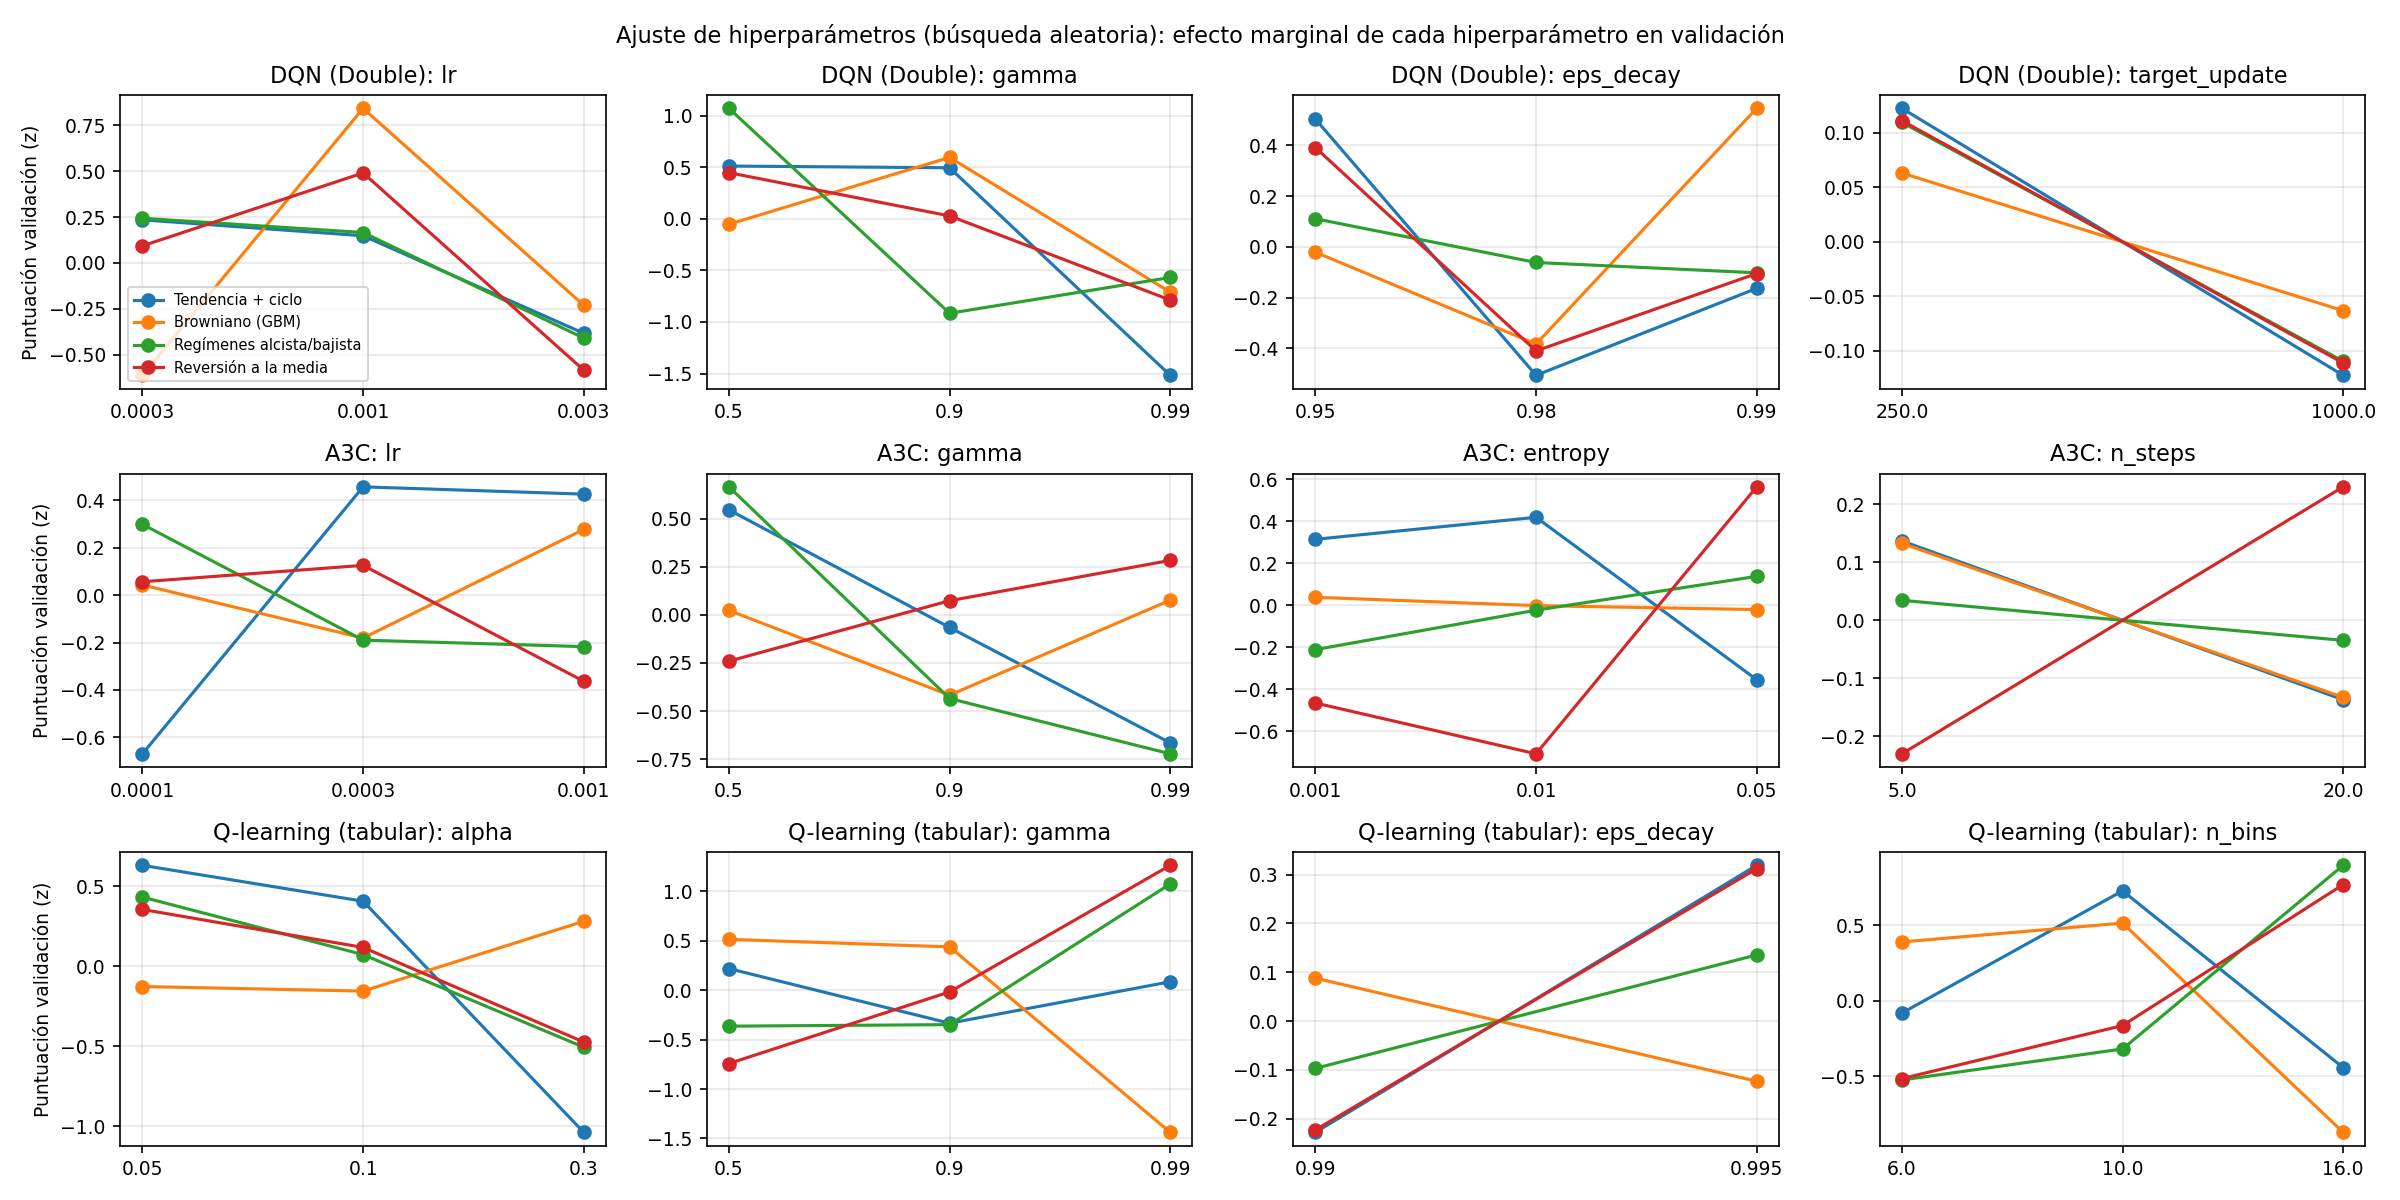

In [4]:
tun = pd.read_csv("results/table_tuning.csv")
best = tun.sort_values("score", ascending=False).groupby(["algo", "gen"]).head(1).sort_values(["algo", "gen"])
display(best.drop(columns=["conf"]).dropna(axis=1, how="all").reset_index(drop=True))
display(Image("results/figures/tuning.png"))

**Lectura del ajuste** (la figura muestra efectos marginales con la puntuación estandarizada por
generador; al ser búsqueda aleatoria hay confusión parcial entre hiperparámetros, así que solo se
interpretan los efectos claros):

- **γ = 0.5 es la elección más frecuente en DQN y A3C** (5 de 8 combinaciones).
  - DQN elige 0.5 en ciclo, reversión y regímenes, y 0.9 en GBM.
  - A3C elige 0.99 en GBM y reversión, pero con ventaja mínima sobre γ = 0.5 (0.118 frente a 0.117 y 0.228
    frente a 0.220).
  - Explicación: el estado (tendencia de 6 precios) no contiene información sobre el futuro lejano, así
    que horizontes largos solo añaden varianza al *target* $r+\gamma\max Q$, que es la suma de muchos
    rendimientos casi independientes.
  - γ = 0.99 es el peor valor en el ciclo para ambos algoritmos.
- **Q-learning prefiere γ alto (0.99) y más bins** en reversión y regímenes. Con tabla no hay
  generalización, y propagar valor entre bins vecinos requiere un horizonte más largo.
- **Tasa de aprendizaje**: 3e-3 es demasiado alta para DQN (inestable en todos los mercados); 3e-4–1e-3 es
  el rango bueno, que coincide con el 1e-3 por defecto que recomendó el profesor.
- **ε**: el decaimiento rápido gana en ciclo y reversión (λ = 0.95, ε ≈ 0.08 a los 50 episodios), porque
  la exploración aleatoria es cara (comisión) y la estructura se aprende pronto. En regímenes gana 0.98 y
  en GBM 0.99; en GBM, además, todas las configuraciones son casi equivalentes.
- **Red objetivo**: copiar cada 250 pasos es algo mejor que cada 1000 (efecto pequeño).

## 7. Resultados principales en test (ejercicios 2 y 4)

Se usan 100 series de test por generador, las mismas para todos los agentes. Para los agentes RL se
da la media sobre 5 semillas de entrenamiento (la sd entre semillas aparece en `log_wealth_sd` y
`sum_reward_sd`). Columnas:

- `ret_median`: rendimiento final mediano (%).
- `log_wealth`: media de $\log(W_T/W_0)$.
- `sum_reward`: $\sum r$, el objetivo que optimiza el agente.
- `beats_bh`: % de series en que el agente supera a B&H.
- `conv_ep` / `conv_time`: episodios / segundos hasta alcanzar el 90% de la mejora en validación.
- `train_time`: tiempo total de entrenamiento en segundos.

In [5]:
tab = pd.read_csv("results/table_main.csv")
cols = ["agente", "ret_median", "log_wealth", "log_wealth_sd", "sum_reward", "sum_reward_sd", "sharpe", "max_dd",
        "trades", "exposure", "beats_bh", "conv_ep", "conv_time", "train_time"]
for gen in GENS:
    display(Markdown(f"#### {GEN_LABELS[gen]}"))
    display(tab[tab.gen == gen][cols].set_index("agente").round(3))

#### Tendencia + ciclo

,ret_median,log_wealth,log_wealth_sd,sum_reward,sum_reward_sd,sharpe,max_dd,trades,exposure,beats_bh,conv_ep,conv_time,train_time
agente,,,,,,,,,,,,,
Aleatorio,984.192,1.457,0.000,2.861,0.000,1.219,79.008,164.922,49.976,6.0,NaN,NaN,NaN
Buy & Hold,3634.081,3.205,0.000,6.014,0.000,1.820,88.967,1.000,100.000,0.0,NaN,NaN,NaN
Momentum,39652.594,5.965,0.000,7.505,0.000,3.050,60.906,92.870,54.672,94.0,NaN,NaN,NaN
Contraria,-95.017,-2.945,0.000,-1.675,0.000,-0.756,95.316,92.770,45.328,0.0,NaN,NaN,NaN
Oráculo miope,29232.596,5.821,0.000,7.773,0.000,2.811,70.029,81.870,69.881,97.0,NaN,NaN,NaN
Siempre fuera,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,10.0,NaN,NaN,NaN
Q-learning (tabular),37656.170,6.057,0.256,7.989,0.157,2.910,68.594,37.638,69.006,99.0,880.0,37.762,89.424
DQN (Double),29311.463,5.887,0.082,7.902,0.062,2.815,70.584,53.054,72.112,99.0,188.0,253.212,533.736
A3C,33254.766,5.593,1.347,7.638,0.910,2.757,70.714,29.950,72.875,99.0,224.0,56.818,122.117


#### Browniano (GBM)

,ret_median,log_wealth,log_wealth_sd,sum_reward,sum_reward_sd,sharpe,max_dd,trades,exposure,beats_bh,conv_ep,conv_time,train_time
agente,,,,,,,,,,,,,
Aleatorio,-13.322,-0.205,0.000,-0.155,0.000,-0.356,36.003,164.922,49.976,31.0,NaN,NaN,NaN
Buy & Hold,-0.768,-0.085,0.000,0.014,0.000,0.022,40.801,1.000,100.000,0.0,NaN,NaN,NaN
Momentum,-20.729,-0.168,0.000,-0.119,0.000,-0.297,35.116,119.360,49.364,35.0,NaN,NaN,NaN
Contraria,-14.679,-0.155,0.000,-0.104,0.000,-0.215,33.985,119.540,50.636,47.0,NaN,NaN,NaN
Oráculo miope,-25.309,-0.305,0.000,-0.251,0.000,-0.552,39.653,237.770,54.583,27.0,NaN,NaN,NaN
Siempre fuera,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,51.0,NaN,NaN,NaN
Q-learning (tabular),-7.989,-0.104,0.059,-0.043,0.033,-0.089,31.017,47.324,61.441,46.0,265.0,12.320,96.996
DQN (Double),-0.395,-0.086,0.001,0.013,0.001,0.020,40.753,1.008,99.674,43.0,128.0,165.422,530.169
A3C,-4.104,-0.096,0.016,-0.006,0.032,-0.012,39.551,17.894,90.225,47.0,40.0,19.739,150.557


#### Reversión a la media

,ret_median,log_wealth,log_wealth_sd,sum_reward,sum_reward_sd,sharpe,max_dd,trades,exposure,beats_bh,conv_ep,conv_time,train_time
agente,,,,,,,,,,,,,
Aleatorio,-13.478,-0.165,0.000,-0.113,0.000,-0.255,31.661,164.922,49.976,0.0,NaN,NaN,NaN
Buy & Hold,-0.425,0.001,0.000,0.105,0.000,0.164,26.153,1.000,100.000,0.0,NaN,NaN,NaN
Momentum,-27.942,-0.319,0.000,-0.269,0.000,-0.616,37.497,126.590,50.016,7.0,NaN,NaN,NaN
Contraria,8.555,0.068,0.000,0.122,0.000,0.269,23.545,126.510,49.984,62.0,NaN,NaN,NaN
Oráculo miope,3.891,0.041,0.000,0.100,0.000,0.208,25.203,147.230,54.613,56.0,NaN,NaN,NaN
Siempre fuera,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,53.0,NaN,NaN,NaN
Q-learning (tabular),27.000,0.233,0.037,0.271,0.043,0.720,17.113,26.894,34.516,95.0,1250.0,64.866,100.180
DQN (Double),24.318,0.235,0.014,0.282,0.015,0.665,19.052,24.798,43.881,96.0,236.0,318.505,552.703
A3C,14.716,0.150,0.024,0.224,0.021,0.419,23.371,28.480,70.403,84.0,920.0,145.002,192.653


#### Regímenes alcista/bajista

,ret_median,log_wealth,log_wealth_sd,sum_reward,sum_reward_sd,sharpe,max_dd,trades,exposure,beats_bh,conv_ep,conv_time,train_time
agente,,,,,,,,,,,,,
Aleatorio,-19.256,-0.266,0.000,-0.222,0.000,-0.533,37.112,164.922,49.976,33.0,NaN,NaN,NaN
Buy & Hold,-12.491,-0.197,0.000,-0.110,0.000,-0.170,44.548,1.000,100.000,0.0,NaN,NaN,NaN
Momentum,-20.517,-0.195,0.000,-0.154,0.000,-0.399,35.057,117.820,50.911,48.0,NaN,NaN,NaN
Contraria,-18.324,-0.236,0.000,-0.190,0.000,-0.422,36.735,117.540,49.089,49.0,NaN,NaN,NaN
Oráculo miope,-19.568,-0.186,0.000,-0.160,0.000,-0.495,30.032,189.900,39.870,48.0,NaN,NaN,NaN
Siempre fuera,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,71.0,NaN,NaN,NaN
Q-learning (tabular),4.480,0.053,0.004,0.077,0.005,0.250,21.092,29.990,46.400,79.0,885.0,42.170,96.770
DQN (Double),-0.474,0.002,0.021,0.040,0.017,0.110,27.880,31.118,60.982,81.0,106.0,140.519,533.967
A3C,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,71.0,80.0,33.981,377.630


### Significación estadística (Wilcoxon pareado sobre 100 series, diferencia de log-riqueza)
- `mean_diff`: media de la diferencia agente − referencia.
- `ci_low`, `ci_high`: IC95% por *bootstrap* sobre series.
- `win_rate`: fracción de series en que gana el agente.
- `hb_low`, `hb_high`: IC95% por *bootstrap* jerárquico, que remuestrea también las semillas y por tanto
  incluye la variabilidad entre entrenamientos.
- `p_holm`: p-valor corregido por Holm dentro de esta tabla.

Es el contraste descriptivo inicial, sobre log-riqueza. Los veredictos definitivos (los de la memoria) usan Σr y
el esquema global de §11: Holm sobre la familia confirmatoria, Benjamini-Hochberg sobre el resto y TOST para
declarar equivalencias.

In [6]:
st = pd.read_csv("results/table_stats.csv")
display(st.round(4))

,gen,agente,vs,mean_diff,ci_low,ci_high,p_wilcoxon,win_rate,hb_low,hb_high,p_holm
0,ciclo,Q-learning (tabular),Buy & Hold,2.853,2.591,3.117,0.000e+00,0.99,NaN,NaN,0.000e+00
1,ciclo,Q-learning (tabular),Aleatorio,4.600,4.379,4.825,0.000e+00,1.00,NaN,NaN,0.000e+00
2,ciclo,Q-learning (tabular),Oráculo miope,0.237,0.079,0.396,2.700e-03,0.60,NaN,NaN,2.920e-02
3,ciclo,DQN (Double),Buy & Hold,2.683,2.416,2.949,0.000e+00,0.99,NaN,NaN,0.000e+00
4,ciclo,DQN (Double),Aleatorio,4.430,4.207,4.665,0.000e+00,1.00,NaN,NaN,0.000e+00
5,ciclo,DQN (Double),Oráculo miope,0.067,-0.036,0.178,3.170e-01,0.52,NaN,NaN,1.000e+00
6,ciclo,DQN (Double),Q-learning,-0.170,-0.290,-0.052,1.050e-02,0.40,-0.422,0.069,9.470e-02
7,ciclo,A3C,Buy & Hold,2.388,2.175,2.611,0.000e+00,0.99,NaN,NaN,0.000e+00
8,ciclo,A3C,Aleatorio,4.136,3.944,4.334,0.000e+00,1.00,NaN,NaN,0.000e+00
9,ciclo,A3C,Oráculo miope,-0.228,-0.368,-0.083,5.100e-03,0.39,NaN,NaN,5.070e-02


### Distribución del exceso de log-riqueza frente a B&H

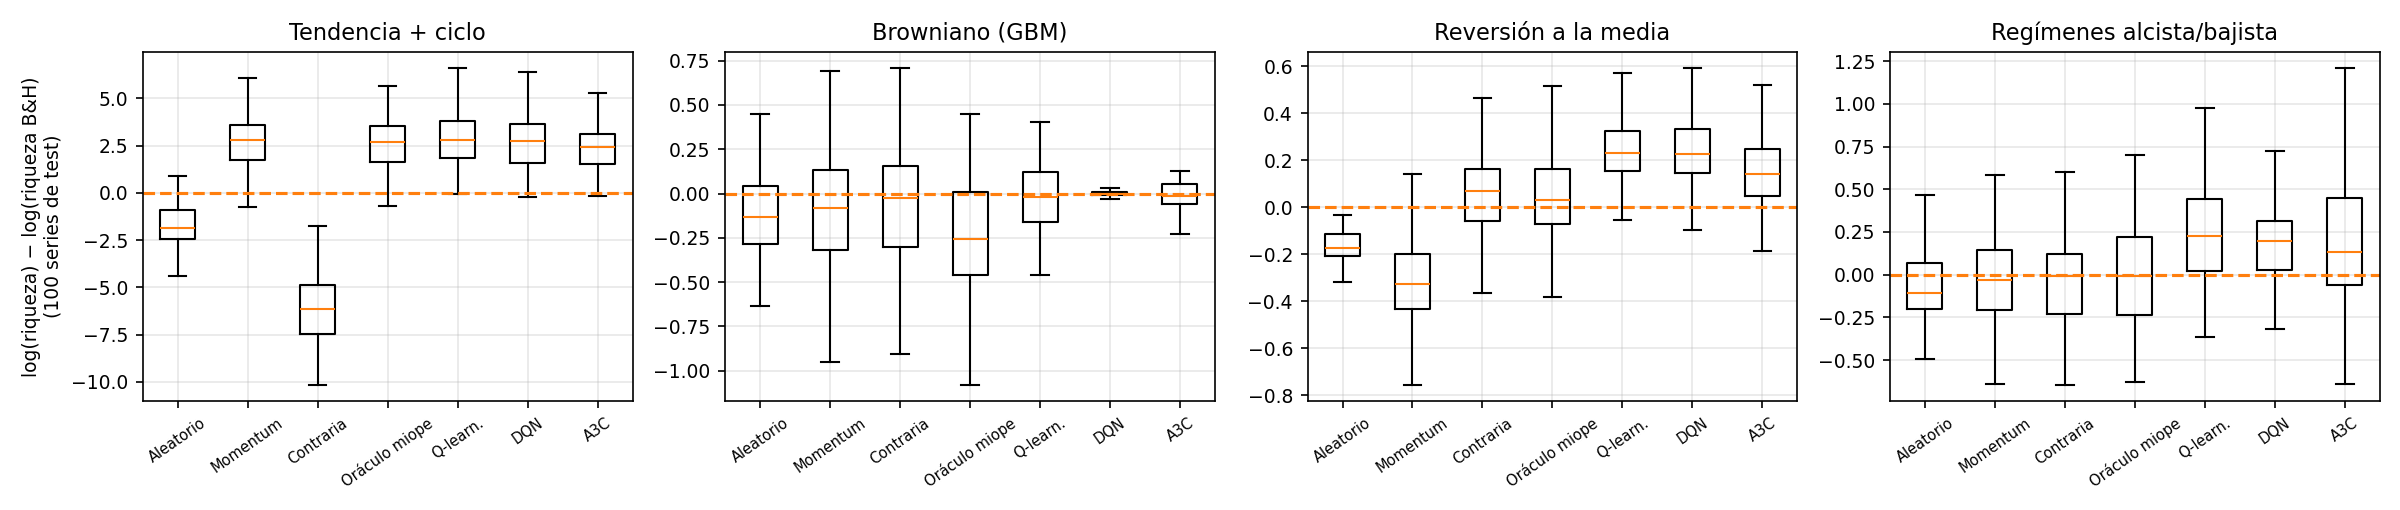

In [7]:
display(Image("results/figures/excess_vs_bh.png"))

### Curvas de aprendizaje y convergencia
Arriba: recompensa total media en validación (política greedy) frente a los episodios (escala log).
Abajo: lo mismo frente al tiempo real. Las líneas discontinuas son las reglas de referencia. La
segunda figura muestra la **G de entrenamiento** con media móvil de 50 episodios, como pidió el profesor.

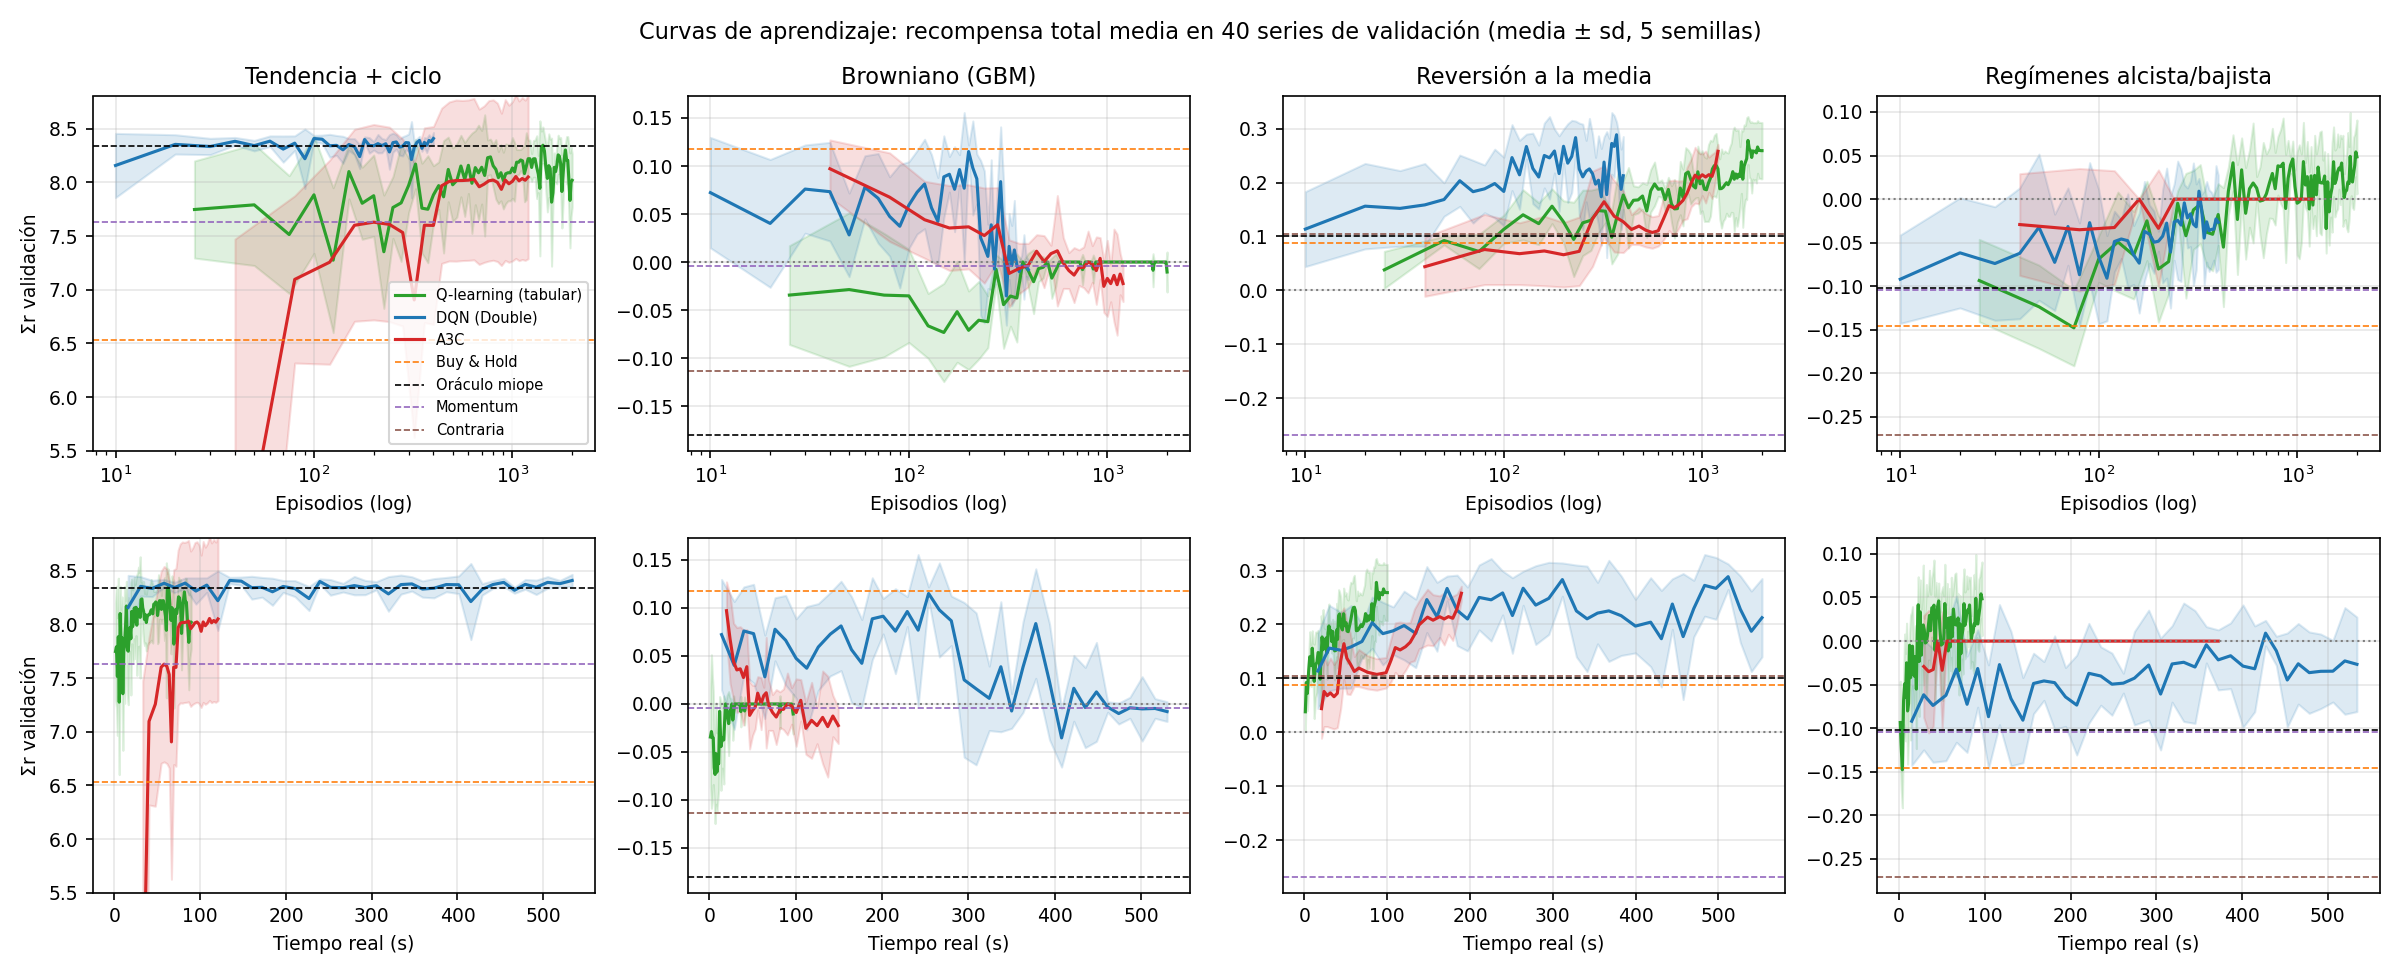

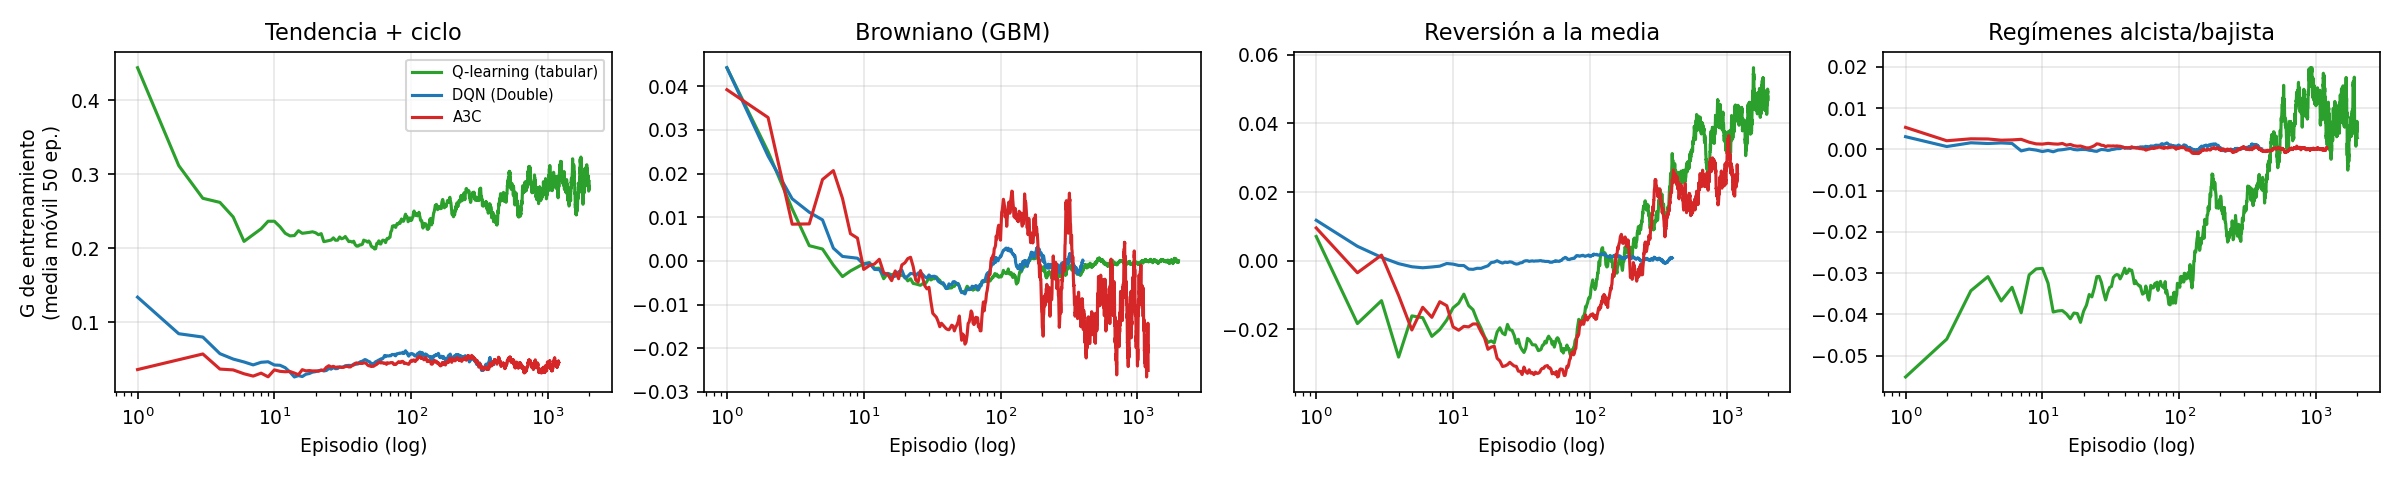

In [8]:
display(Image("results/figures/learning_curves.png"))
display(Image("results/figures/train_G.png"))

### ¿Es la estrategia aprendida la esperada? Mapas de política
Para cada valor de la tendencia normalizada se muestra la fracción de las 5 semillas cuya política
greedy deja al agente **invertido**:

- Línea continua: el agente parte sin posición (¿compra?).
- Línea discontinua: el agente parte con posición (¿mantiene?).
- Curva punteada negra: $E[r_{t+1}|\text{tendencia}]$ estimada en entrenamiento.

En regímenes, A3C no compra nunca (su curva de "mantiene" no llega a usarse).

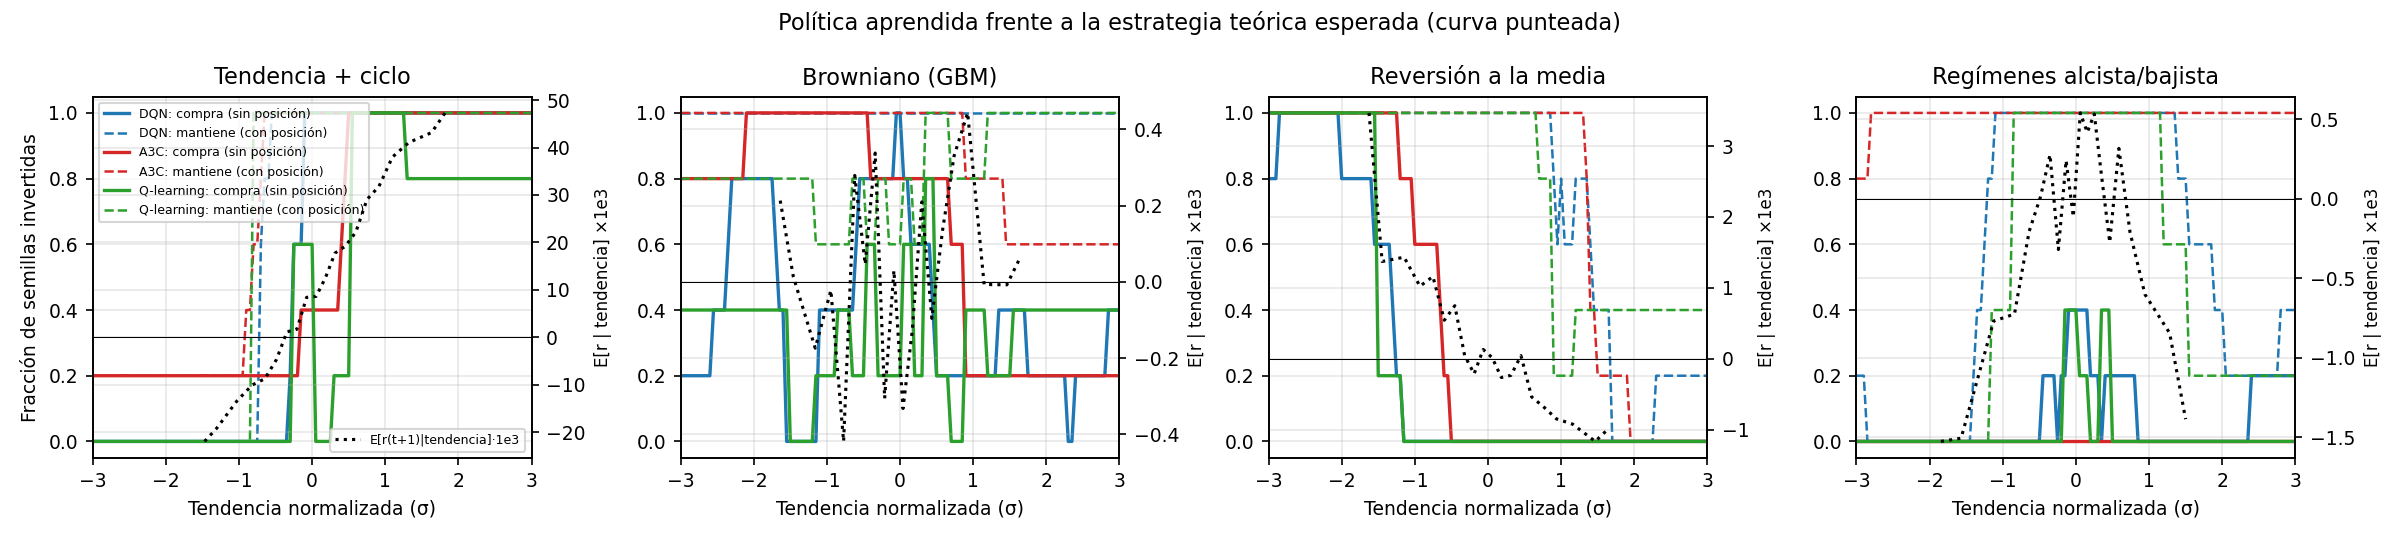

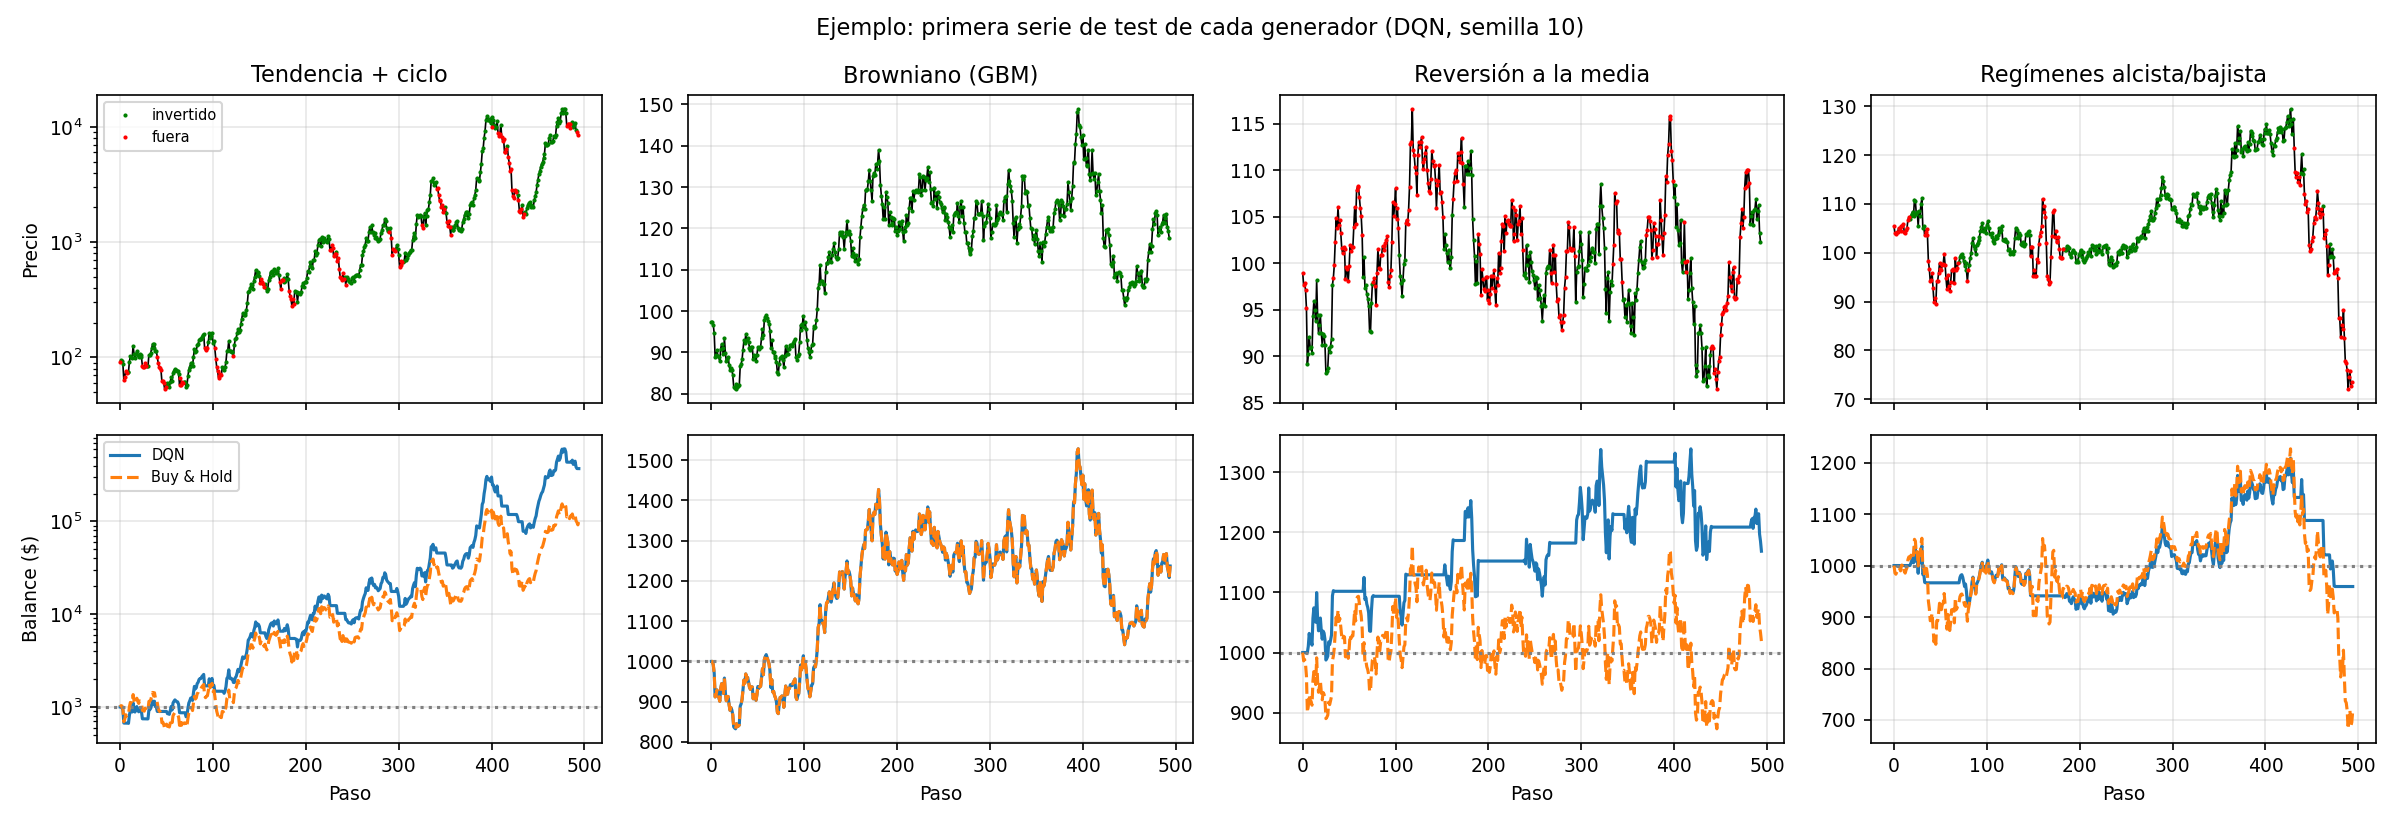

In [9]:
display(Image("results/figures/policy_maps.png"))
display(Image("results/figures/episode_examples.png"))

### 7.1 Análisis crítico por mercado

**Tendencia + ciclo (señal fuerte de momentum).**
- Los tres agentes aprenden *momentum con histéresis*: compran cuando la tendencia es positiva y
  mantienen la posición hasta una tendencia ligeramente negativa (≈ −0.5σ). Es exactamente la
  estructura de $E[r|x]$ (cruza el cero algo por debajo de $x=0$) más la banda que impone la comisión.
- Todos baten a B&H en el 99% de las series (Wilcoxon $p\approx0$; exceso de log-riqueza de +2.4 a +2.9,
  es decir, riqueza final entre 11 y 17 veces la de B&H).
- Frente al **oráculo miope** (que conoce el generador): Q-learning lo supera (+0.24, p = 0.003), DQN
  no se distingue de él (+0.07, p = 0.32: no concluyente) y A3C queda por debajo (−0.23) por **una semilla que colapsó** en "siempre
  dentro" en los primeros 40 episodios. Es un óptimo local típico del gradiente de política con entropía
  baja (β = 0.001). Las 4 semillas restantes de A3C están al nivel de las mejores (Σr ≈ 7.9–8.1).
- Los agentes operan **menos que el oráculo** (30–53 operaciones frente a 82) porque internalizan la
  comisión.

**GBM (sin señal).**
- El resultado correcto es *no* encontrar estrategia. DQN converge en las 5 semillas a **B&H exacto**
  (1 operación; en §11 es *equivalente* a B&H por TOST). Es racional: la deriva aritmética
  es positiva ($\mu=10^{-4}$), así que estar invertido maximiza $E[\sum r]$.
- La **mediana** de la riqueza de B&H es menor que 1 por el arrastre de volatilidad
  ($\mu-\sigma^2/2<0$): ejemplo claro de que **la recompensa del entorno (aritmética) no es la riqueza
  (geométrica)**.
- A3C y Q-learning alternan entre B&H y políticas que sobreoperan el ruido (Q-learning: 47
  operaciones), sin diferencia significativa con B&H.
- Todas las reglas activas pierden por comisión. El oráculo (−0.25) es el peor: cree ver señal en el
  ruido de muestreo de la estimación.

**Reversión a la media (señal contraria).**
- DQN y Q-learning aprenden la estrategia **contraria con histéresis**: compran con tendencia < −1.2σ y
  venden con > +1σ. Operan solo en los extremos, donde $|E[r|x]|$ supera a la comisión (25–27
  operaciones frente a 127 de la regla contraria).
- Resultado: +24% / +27% de rendimiento mediano frente a −0.4% de B&H y +8.6% de la regla contraria;
  baten a B&H en el 95–96% de las series.
- DQN y Q-learning no se distinguen (p = 0.92), pero tampoco son equivalentes: en §11 el contraste es
  **no concluyente** (el IC90% se sale de ±δ).
- A3C es correcto pero peor (+14.7%), y su mejor *checkpoint* es el último: no había convergido (ver la
  iteración 2 en §8).

**Regímenes (señal no lineal y débil).**
- Es el mercado más difícil: la ventaja máxima es ≈0.3‰ por paso frente a un ruido del 1–2.5%. Todas las
  reglas pierden, y la referencia trivial es "siempre fuera" (Σr = 0).
- Q-learning (+0.077) y DQN (+0.040) aprenden la **banda** esperada: compran solo con tendencia moderada
  y mantienen en una banda más ancha. Ninguna regla lineal puede representar esta política.
- A3C converge en las 5 semillas a "**siempre fuera**". Es una solución segura (bate a B&H en el 71% de
  las series), pero el gradiente de política, con una ventaja tan ruidosa, no consigue separar una
  mejora tan pequeña de la varianza.

**DQN frente a Q-learning (pregunta del profesor).**
- Resultado con el esquema definitivo de §11 (Σr, familia confirmatoria con Holm, TOST):
  - **GBM**: DQN gana (Q-learning sobreopera el ruido);
  - **regímenes**: Q-learning gana (DQN pierde);
  - **ciclo y reversión**: **no concluyente**. No es un empate: el IC90% se sale de ±δ, y con 5 semillas el
    efecto mínimo detectable es mayor que δ (la mayor parte de la incertidumbre viene de las semillas).
- En log-riqueza (tabla anterior) el ciclo es significativo sin corregir (p = 0.011), pero no tras Holm ni con el
  IC jerárquico, que remuestrea semillas y series ([−0.42, +0.07]).
- No es un defecto de implementación sino una propiedad del problema:
  - El estado tiene **una sola variable continua**, y 10–16 bins equiprobables apenas pierden
    información.
  - Q-learning tabular converge al óptimo con α decreciente, sin el sesgo de la aproximación de
    funciones.
  - La ventaja de la red (generalizar entre estados) solo aparecería con estados de mayor dimensión.
- DQN es claramente superior en **eficiencia muestral**: alcanza el 90% de su mejora en 106–236
  episodios, frente a 265–1250 de Q-learning. Además es más robusto en GBM.
- Q-learning es ≈22–25 veces más barato por episodio (≈0.05 s frente a ≈1.3 s con la máquina cargada;
  0.023 s frente a 0.51 s sin carga, §8.4).

## 8. Experimentos más allá de los mínimos

### 8.1 Ablaciones e iteraciones de mejora
- **Variantes de DQN**, con la configuración óptima de cada mercado, 250 episodios y 2 semillas:
  - *vanilla*: sin red objetivo, como el notebook del profesor;
  - con red objetivo;
  - Double DQN.
- **γ ∈ {0, 0.5, 0.9, 0.99}** en DQN. γ = 0 es un agente miope: solo ve la comisión inmediata.
- **Iteración 2 de DQN en regímenes**: 1000 episodios en lugar de 400 (5 semillas), para comprobar si la
  diferencia con Q-learning se debe a *muestras* o a *capacidad*.
- **Iteración 2 de A3C en reversión**: 3000 episodios en lugar de 1200 (5 semillas), porque la curva
  seguía subiendo.
- **Iteración 2 de A3C en regímenes**: A3C colapsaba en "siempre fuera" en las 5 semillas. Se prueban 3
  configuraciones con 3000 episodios (5 semillas cada una): A = (α 3e-4, γ 0.9, β 0.01), B = (α 3e-4,
  γ 0.99, β 0.01), C = (α 1e-4, γ 0.99, β 0.05). La configuración se elige **solo por validación**.
- **Workers de A3C** (1, 2, 4, 8 y 16; 800 episodios; con la máquina sin otra carga): tiempo real de
  entrenamiento y calidad alcanzada.

,kind,name,gen,sum_reward,sum_reward_sd,log_wealth,trades,exposure,conv_ep,conv_time,train_time,train_span,final_val,final_val_sd
0,a3cepisodes,a3cepisodes_3000_reversion,reversion,0.278,0.007,0.222,23.654,52.402,1500.0,132.876,222.828,201.662,0.245,0.020
1,a3creg,a3creg_A_regimenes,regimenes,0.013,0.028,0.006,3.584,10.563,564.0,49.930,198.347,184.821,0.000,0.000
2,a3creg,a3creg_B_regimenes,regimenes,-0.004,0.008,-0.005,0.306,1.750,732.0,88.613,290.462,249.228,-0.048,0.050
3,a3creg,a3creg_C_regimenes,regimenes,0.000,0.000,0.000,0.000,0.000,312.0,37.196,243.333,226.988,-0.072,0.052
4,dqnvar,dqnvar_double_ciclo,ciclo,7.973,0.038,5.979,50.105,71.405,60.0,86.151,430.088,429.392,8.390,0.023
5,dqnvar,dqnvar_double_gbm,gbm,0.013,0.000,-0.085,1.020,99.585,110.0,166.146,442.923,440.256,0.038,0.049
6,dqnvar,dqnvar_double_regimenes,regimenes,0.037,0.051,0.025,6.380,21.605,120.0,340.912,502.524,501.712,-0.010,0.008
7,dqnvar,dqnvar_double_reversion,reversion,0.276,0.010,0.230,35.885,41.821,185.0,479.382,560.258,559.909,0.273,0.064
8,dqnvar,dqnvar_target_ciclo,ciclo,7.891,0.032,5.878,52.940,72.060,35.0,40.199,360.204,359.984,8.322,0.043
9,dqnvar,dqnvar_target_gbm,gbm,0.013,0.000,-0.085,1.000,99.736,75.0,104.901,357.224,357.024,0.016,0.025


,name,val,test_sum_reward,test_sd,trades,exposure,n,elegida_por_validacion
0,a3creg_A_regimenes,0.017,0.013,0.028,3.584,10.563,5,True
1,a3creg_B_regimenes,0.003,-0.004,0.008,0.306,1.750,5,False
2,a3creg_C_regimenes,0.000,0.000,0.000,0.000,0.000,5,False


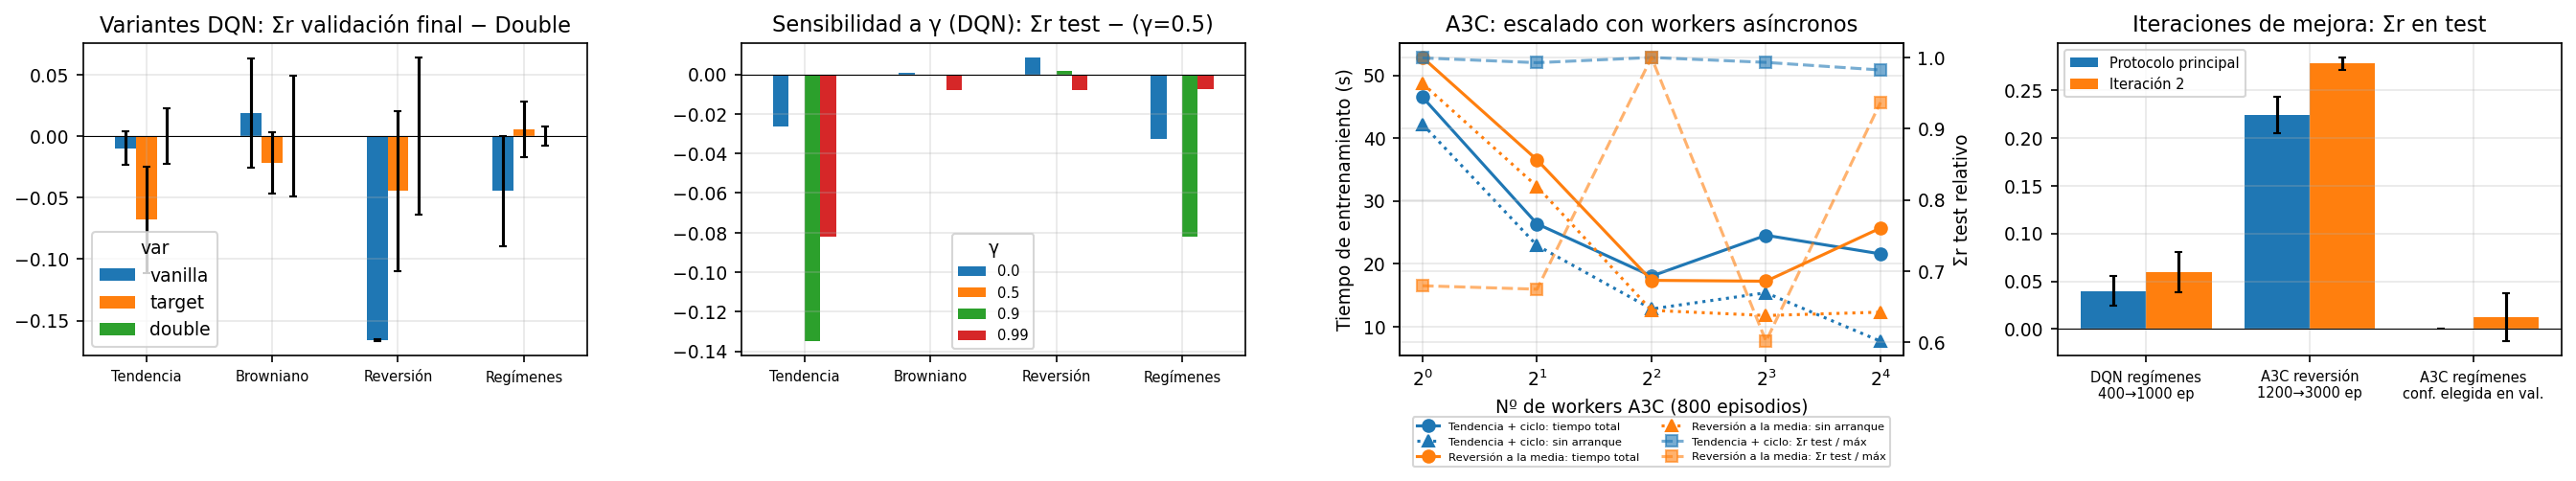

In [10]:
abl = pd.read_csv("results/table_ablations.csv")
display(abl.round(3))
display(pd.read_csv("results/table_a3c_regimenes_iter.csv").round(3))
display(Image("results/figures/ablations.png"))

### 8.2 Generalización entre mercados
Cada agente entrenado en un generador se evalúa en el test de **todos** los generadores. La métrica es
el exceso medio de log-riqueza frente a B&H; la diagonal corresponde a evaluar dentro de la misma
distribución.

,ciclo,gbm,reversion,regimenes
dqn_ciclo,2.682,0.000,-0.000,-0.000
dqn_gbm,-0.301,-0.001,0.002,-0.002
dqn_reversion,-5.217,0.023,0.233,0.058
dqn_regimenes,-2.207,-0.002,-0.182,0.199
a3c_ciclo,2.388,0.010,-0.013,0.029
a3c_gbm,-2.488,-0.011,0.032,0.016
a3c_reversion,-6.233,0.012,0.148,0.071
a3c_regimenes,-3.205,0.085,-0.001,0.197


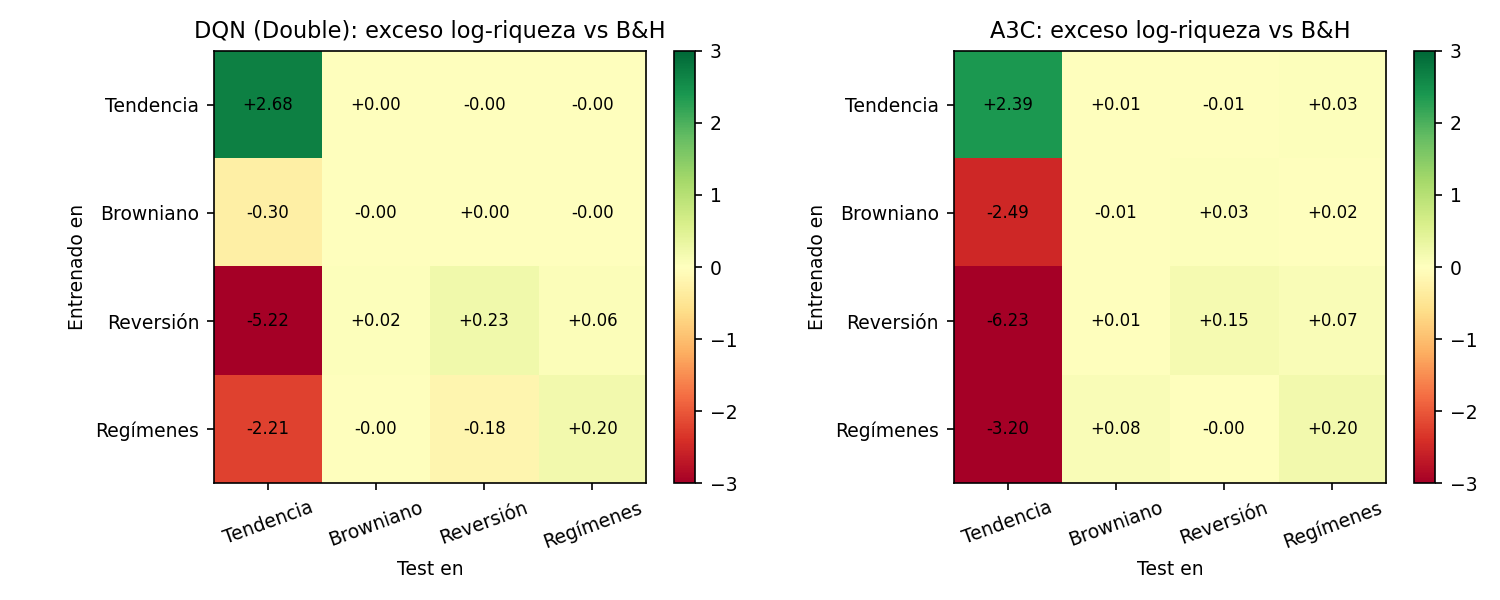

In [11]:
display(pd.read_csv("results/table_generalization.csv", index_col=0).round(3))
display(Image("results/figures/generalization.png"))

### 8.3 Serie real: S&P 500
- **Entrenamiento**: ventanas aleatorias de 500 días del S&P 500 2001–2010 (ficheros del profesor).
- **Test**: año 2011 completo (252 días), **fuera de muestra** y posterior al periodo de entrenamiento.
- **Hiperparámetros**: los elegidos para GBM, el generador más parecido a un mercado real.
- 3 semillas por algoritmo.

In [12]:
display(pd.read_csv("results/table_sp500.csv").round(3))

,agente,ret,ret_sd,sum_reward,trades,exposure,sharpe,max_dd
0,Q-learning (tabular),2.817,9.491,0.038,43.333,29.268,0.232,14.888
1,DQN (Double),12.772,7.539,0.127,45.333,32.520,0.962,7.585
2,A3C,0.719,6.184,0.024,33.333,62.195,0.126,16.276
3,Aleatorio,-9.085,0.000,-0.089,84.250,51.728,-0.498,20.658
4,Buy & Hold,-1.056,0.000,0.016,1.000,100.000,0.072,19.388
5,Momentum,-16.787,0.000,-0.172,65.000,54.065,-1.155,19.523
6,Contraria,4.402,0.000,0.059,66.000,45.935,0.337,16.121


**¿Habilidad o suerte?** Con una sola serie no hay test pareado posible. Como contraste, para cada ejecución
se simulan 20 000 estrategias aleatorias de Markov (entrar y salir con probabilidades fijas) con **la misma
exposición media y el mismo número esperado de operaciones** que el agente, sobre la misma serie de 2011.
El p-valor es la fracción de estrategias aleatorias que igualan o superan el rendimiento del agente
(`python -m experiments.sp500_null`).

In [13]:
display(pd.read_csv("results/table_sp500_null.csv").round(3))

,agente,seed,ret,trades,exposure,null_ret_median,null_ret_p95,null_trades,null_exposure,p_value
0,A3C,10,-5.661,43.0,60.163,-5.050,12.961,42.881,59.774,0.524
1,A3C,11,1.132,35.0,55.691,-4.525,13.452,34.892,55.089,0.293
2,A3C,12,6.685,22.0,70.732,-3.550,12.921,22.120,69.722,0.142
3,DQN (Double),10,12.805,48.0,26.423,-5.015,11.494,47.722,26.249,0.038
4,DQN (Double),11,5.217,48.0,28.455,-5.134,11.426,47.700,28.316,0.145
5,DQN (Double),12,20.295,40.0,42.683,-4.453,13.748,39.801,42.299,0.014
6,Q-learning (tabular),10,-1.065,38.0,28.049,-3.962,12.020,37.754,27.783,0.376
7,Q-learning (tabular),11,13.633,44.0,35.366,-4.837,12.608,43.719,35.141,0.041
8,Q-learning (tabular),12,-4.116,48.0,24.390,-4.848,11.081,47.739,24.265,0.470


### 8.4 Lectura crítica de los experimentos adicionales

**Variantes de DQN (red objetivo y Double DQN).**
- En test, con el mejor *checkpoint* según validación, las diferencias son pequeñas y de signo variable:
  - reversión: 0.276 / 0.290 / 0.276;
  - ciclo: 7.88 / 7.89 / 7.97;
  - GBM: vanilla 0.005 frente a 0.013, porque opera algo más;
  - regímenes: vanilla 0.075 frente a 0.037; con 2 semillas no es fiable.
- La diferencia aparece **al final del entrenamiento**, en la columna `final_val`. En reversión a la media:
  - *vanilla*: 0.107, y la desviación entre semillas casi nula indica que el agente ha colapsado;
  - con red objetivo: 0.228;
  - Double DQN: 0.273.
- Es la inestabilidad que se vio en clase: sin red objetivo el agente **encuentra** buenas políticas pero **no
  las mantiene**, porque el *target* se mueve con la propia red.
- La parada temprana con validación enmascara esa inestabilidad. Por eso forma parte del protocolo, y por eso
  la comparación justa es la curva completa y no solo el mejor punto.

**Factor de descuento γ.** Este es el resultado menos intuitivo:
- **γ = 0 ya funciona bien en ciclo y reversión** (Σr 7.95 y 0.284). Q(s, a) se reduce al rendimiento
  esperado del siguiente paso menos la comisión, y en esos mercados la tendencia predice precisamente el
  siguiente rendimiento.
- La comisión aparece en la recompensa inmediata, y la acción "mantener" no paga comisión. Por eso incluso el
  agente miope desarrolla cierta histéresis.
- γ = 0 es **el peor en regímenes** (0.004 frente a 0.037 con γ = 0.5). Allí la información útil es la
  *persistencia* del régimen, y eso es exactamente lo que el descuento propaga.
- γ = 0.99 opera de más en GBM (7 operaciones frente a 1). El *target* acumula muchos rendimientos ruidosos y
  su varianza crece aproximadamente como 1/(1 − γ²).
- γ = 0.5 es un buen compromiso: coincide con la elección del ajuste en 5 de 8 casos.

**Reproducibilidad.** Las filas `gamma_0.5_ciclo` y `dqnvar_double_ciclo` son dos ejecuciones independientes
con la misma configuración y la misma semilla, y dan resultados **idénticos** al último decimal.

**Iteraciones de mejora sobre los puntos débiles.**
- A3C en reversión con 3000 episodios alcanza Σr = 0.278, al nivel de DQN (0.282). La diferencia de la tabla
  principal se debía a falta de muestras, no a una incapacidad del método.
- A3C en regímenes se probó con 3 configuraciones nuevas (lr 3·10⁻⁴ o 10⁻⁴, γ 0.9 o 0.99, entropía 0.01 o
  0.05) y 3000 episodios × 5 semillas. La configuración elegida por **validación** (A) solo llega a Σr = 0.013
  en test, frente a 0.077 de Q-learning.
- Con una señal de ≈0.3‰ por paso, el gradiente de política (ventaja estimada con un crítico ruidoso) no
  distingue la banda rentable del "siempre fuera". Es una limitación real del método en este problema y se
  reporta tal cual.
- DQN en regímenes con 1000 episodios (5 semillas) pasa de Σr = 0.040 a **0.059 ± 0.024**: recorta la mitad
  de la distancia con Q-learning (0.077). En regímenes, a DQN le faltaban muestras. El resto de la diferencia
  es coherente con la conclusión de la sección 7: con un estado de una sola variable, la tabla no pierde nada
  frente a la red. La convergencia también es lenta (90% de la mejora en el episodio ≈470): la señal es tan
  débil que cada actualización aporta poca información.

**Escalado de A3C con el número de workers** (800 episodios, 1 semilla):
- El tiempo de entrenamiento propiamente dicho, del primer al último episodio, baja:
  - en el ciclo, de 42 s con 1 worker a 7.6 s con 16 (×5.5);
  - en reversión, de 49 s a ≈12 s (×4.1), sin mejora a partir de 4–8 workers.
  
  La aceleración es sublineal. Las causas probables son la contención al escribir en los pesos compartidos y
  la validación periódica en el proceso principal.
- La calidad no se degrada sistemáticamente con más workers:
  - ciclo: Σr de 8.04 a 8.18 en todos los casos;
  - reversión: de 0.13 a 0.22, sin tendencia; con 1 semilla y solo 800 episodios es ruido.
  
  La "obsolescencia" de los gradientes asíncronos no perjudica de forma visible en este problema.
- Con *spawn* en Windows, cada worker importa PyTorch. Arrancar 16 procesos cuesta ≈10 s, que en
  entrenamientos de 20–50 s es un coste comparable al del propio aprendizaje.

**Tiempos con la máquina sin carga.** Los tiempos de la sección 7 se midieron con ≈20 entrenamientos
simultáneos y están inflados de forma desigual. Se repitió una ejecución por algoritmo y mercado (semilla 10,
configuración final) con la máquina libre, una detrás de otra (`results/timing/`, celda siguiente; son los
tiempos de la Tabla 4 de la memoria). En el ciclo:
- DQN, 400 episodios: 203 s (0.51 s/episodio), frente a 520 s con carga;
- Q-learning, 2000 episodios: 47 s (0.023 s/episodio), frente a 88 s;
- A3C con 4 workers, 1200 episodios: 37 s (0.031 s/episodio de tiempo real), frente a 122 s.

La relación de coste por episodio DQN/Q-learning (≈22) confirma la estimación de la sección 7. DQN y
Q-learning reproducen **exactamente** el mismo mejor *checkpoint* (episodio y Σr de validación) que con
carga: el resultado es determinista. A3C no lo hace: el orden de las actualizaciones asíncronas depende del
planificador del sistema operativo, que es una fuente de varianza propia de A3C.

**Generalización entre mercados.**
- La diagonal de DQN es positiva donde hay señal: ciclo +2.68, reversión +0.23, regímenes +0.20. En GBM vale
  ≈0, que es lo esperado.
- Fuera de la diagonal los valores son pequeños (|Δ| < 0.09), salvo los cruces con el ciclo, que son muy
  negativos. Una política contraria (entrenada en reversión) aplicada al ciclo pierde 5.2 en log-riqueza
  frente a B&H.
- El agente del ciclo aplicado a reversión se comporta como B&H (Δ ≈ 0). Normaliza con la σ del ciclo, que es
  ≈6 veces mayor, así que compra en cuanto la tendencia es positiva. Su umbral de venta (≈−0.5σ del ciclo)
  equivale a ≈−3σ de reversión, de modo que casi nunca vende.
- Algunos cruces son ligeramente positivos (A3C de regímenes en GBM: +0.08), pero con 100 series y efectos de
  ese tamaño no son concluyentes.
- Las políticas aprendidas son **específicas del proceso generador**. Un agente útil en real necesitaría
  identificar el régimen (más variables de estado) o entrenarse con varios generadores.

**S&P 500 2011.**
- Con los hiperparámetros de GBM, DQN termina en +12.8% ± 7.5 (3 semillas) frente a −1.1% de B&H, con
  exposición baja y menos de la mitad de *drawdown*.
- Es una sola serie de 252 días, y la dispersión entre semillas es del orden del efecto.
- Frente a estrategias aleatorias con la misma exposición y el mismo número de operaciones, las tres
  semillas de DQN obtienen p = 0.038, 0.145 y 0.014: superan al 86–99% de los "monos" equiparables. Las
  de Q-learning (p = 0.38, 0.04, 0.47) y A3C (p = 0.52, 0.29, 0.14) no se distinguen del azar.
- Pero se han contrastado 9 ejecuciones. Con el esquema global de §11 (Benjamini-Hochberg sobre todos los
  contrastes exploratorios) solo una ejecución de DQN sigue siendo significativa. Lo interpretamos como
  **indicio** a favor de DQN, no como evidencia de una estrategia rentable.

## 9. Ampliación: ¿cuánto queda por ganar y de qué depende?

Las secciones 7–8 responden a lo que pide el enunciado. Esta sección plantea siete preguntas más exigentes,
con el mismo protocolo (ajuste solo con validación, test de 100 series mirado una vez, varias semillas) y
**un solo cambio cada vez** respecto a la configuración ajustada:

| § | Pregunta | Experimento |
|---|---|---|
| 9.1 | ¿Qué parte del óptimo *alcanzable con este estado* capturan los agentes? | 6 familias de reglas de 1–4 umbrales, ajustadas por búsqueda exhaustiva en series de **entrenamiento** |
| 9.2 | ¿Limita el estado del enunciado? | Estado enriquecido causal (ventana de 10 rendimientos, P/MA30, volatilidad 20) en DQN, A3C y PPO |
| 9.3 | ¿Puede un único agente operar en los cuatro mercados? | DQN entrenado alternando generadores |
| 9.4 | ¿Cómo responde la política a la comisión? | 4 comisiones (0, 0.05, 0.1, 0.5%), con reglas re-ajustadas en cada una |
| 9.5 | ¿Y si el agente es averso al riesgo? | Recompensa logarítmica y media-varianza |
| 9.6 | ¿Un algoritmo más moderno lo hace mejor? | PPO (con entorno vectorizado verificado) y Dueling DQN |
| 9.7 | ¿Siguen en pie las conclusiones con una estadística más estricta? | *Bootstrap* jerárquico (semillas × series); el esquema definitivo está en §11 |

Todo se reproduce con `python -m experiments.rules_eval`, `python -m experiments.main ext_dqn|ext_a3c|ext_ppo|ext_ppo_feat|ext_dqn_feat_long 8`,
`python -m experiments.main final 4 ppo` y `python -m experiments.analysis_ext`. Los tests de `tests/test_core.py` (38) verifican, entre otras cosas:
- el entorno con comisión variable, que con 0.1% reproduce exactamente el original;
- el entorno vectorizado de PPO, idéntico al original;
- la causalidad de las nuevas variables, que no usan precios futuros.

### 9.1 ¿Bate el RL a la mejor regla? El techo alcanzable con este estado

**Teoría.** El estado del enunciado es (z, posición), con z la tendencia normalizada. Una política
estacionaria determinista es, por tanto, un par de conjuntos:
- *comprar si z ∈ B* cuando se está fuera;
- *vender si z ∈ S* cuando se está dentro.

Si la ventaja de estar invertido, Q(z, dentro) − Q(z, fuera), es **monótona** en z (ciclo, reversión), los dos
conjuntos son semirrectas. La política óptima *dentro de las que dependen solo de la observación* es entonces
una **regla de histéresis de dos umbrales**:
- *momentum*: comprar si z > a, vender si z < b, con b ≤ a;
- *contraria*: el caso simétrico.

La comisión hace que b < a: la zona entre ambos umbrales es una **zona de no operar**. Si la relación es
**unimodal** (U invertida, como en regímenes, §2), hace falta una **banda con histéresis** de cuatro umbrales.

Así que basta una búsqueda exhaustiva en una rejilla de umbrales para tener una referencia mucho más dura que
las reglas miopes de la sección 7. Es el **techo práctico** de lo que cualquier agente sin memoria puede
conseguir con esta observación.

**Protocolo.**
- Seis familias (`rl_trading/rules.py`):
  - umbral simple (*mom1*, *con1*);
  - histéresis (*mom_h*, *con_h*);
  - banda (*band*);
  - banda con histéresis (*band_h*, 1365 candidatos).
- Umbrales en múltiplos de σ: 25 valores en ±3σ, o 13 en *band_h*.
- Se ajustan maximizando la Σr media en **100 series de entrenamiento** (bloque de semillas 97, disjunto de
  validación y test).
- Se elige la familia por validación y se evalúa una vez en test.
- Las comparaciones con los agentes son pareadas por serie (Wilcoxon sobre la media de semillas), con IC por
  *bootstrap* jerárquico y Holm sobre todas las comparaciones de la tabla.

In [14]:
rules = pd.read_csv("results/table_rules.csv")
display(rules[rules.elegida | rules.regla.isin(["mom_h", "con_h", "band_h"])].round(3))
rvr = pd.read_csv("results/table_rules_vs_rl.csv")
display(rvr.round(4))

,gen,regla,elegida,a,b,c,d,fit,val,sum_reward,log_wealth,trades,exposure
2,ciclo,mom_h,True,0.25,-0.75,NaN,NaN,8.458,8.447,8.120,6.279,38.37,65.603
3,ciclo,con_h,False,3.00,3.00,NaN,NaN,6.131,6.463,5.960,3.156,2.70,99.789
5,ciclo,band_h,False,0.50,3.00,-1.0,3.0,8.353,8.309,8.083,6.204,28.19,66.779
8,gbm,mom_h,False,-2.00,-3.00,NaN,NaN,0.049,0.118,0.017,-0.082,2.22,99.713
9,gbm,con_h,True,-2.50,2.75,NaN,NaN,0.107,0.047,0.006,-0.038,1.94,43.986
11,gbm,band_h,False,-3.00,-2.50,-3.0,2.5,0.080,0.061,-0.008,-0.039,2.58,30.761
14,reversion,mom_h,False,-2.00,-3.00,NaN,NaN,0.105,0.080,0.100,-0.003,2.41,99.684
15,reversion,con_h,True,-1.25,1.50,NaN,NaN,0.333,0.308,0.277,0.216,23.75,57.540
17,reversion,band_h,False,-3.00,-1.50,-3.0,1.5,0.316,0.303,0.278,0.229,21.29,46.443
20,regimenes,mom_h,False,0.25,-1.25,NaN,NaN,0.031,-0.036,-0.062,-0.121,31.23,78.310


,gen,agente,vs,metric,diff,p,ci_low,ci_high,win,p_holm
0,ciclo,Q-learning,regla mom_h,sum_reward,-1.312e-01,4.650e-02,-3.186e-01,0.031,42.0,0.876
1,ciclo,Q-learning,regla mom_h,log_wealth,-2.216e-01,8.000e-04,-4.612e-01,0.007,42.0,0.020
2,ciclo,DQN,regla mom_h,sum_reward,-2.175e-01,2.100e-03,-3.633e-01,-0.074,35.0,0.052
3,ciclo,DQN,regla mom_h,log_wealth,-3.916e-01,0.000e+00,-5.471e-01,-0.237,28.0,0.000
4,ciclo,A3C,regla mom_h,sum_reward,-4.817e-01,0.000e+00,-1.351e+00,-0.002,14.0,0.000
5,ciclo,A3C,regla mom_h,log_wealth,-6.861e-01,0.000e+00,-1.948e+00,0.037,8.0,0.000
6,ciclo,PPO,regla mom_h,sum_reward,-4.060e-02,2.058e-01,-1.118e-01,0.024,50.0,1.000
7,ciclo,PPO,regla mom_h,log_wealth,8.000e-03,7.362e-01,-5.810e-02,0.083,53.0,1.000
8,gbm,Q-learning,regla con_h,sum_reward,-4.840e-02,1.510e-02,-1.025e-01,0.005,36.0,0.331
9,gbm,Q-learning,regla con_h,log_wealth,-6.520e-02,2.100e-03,-1.276e-01,0.002,33.0,0.052


**Resultados.**

| Mercado | Regla elegida (umbrales en σ) | Σr ajuste → test | Mejor agente (estado base) | Δ Σr agente − regla [IC jerárquico] |
|---|---|---|---|---|
| Tendencia+ciclo | *mom_h*: compra z > 0.25, vende z < −0.75 | 8.46 → **8.120** | PPO 8.079 | −0.041 [−0.11, +0.02] |
| GBM | *con_h*: compra z < −2.5, vende z > 2.75 (solo extremos) | 0.11 → 0.006 | DQN 0.013 | +0.007 [−0.06, +0.07] |
| Reversión | *con_h*: compra z < −1.25, vende z > 1.5 | 0.33 → **0.277** | PPO 0.289 / DQN 0.282 | +0.012 [−0.02, +0.05] |
| Regímenes | *band_h*: compra si −0.5 < z < 0, mantiene si −1.5 < z < 1.5 | 0.069 → 0.016 | Q-learning 0.077 | **+0.061** [+0.02, +0.10] |

**Lectura.**
- **La regla óptima es la estructura que predice la teoría.**
  - En el ciclo: *momentum* con histéresis, con umbral de compra (+0.25σ) mayor que el de venta (−0.75σ).
  - En reversión: contraria con histéresis.
  - En regímenes: una banda asimétrica.
  
  Es la misma forma que los mapas de política de §7, lo que confirma que los agentes aprendieron la
  estructura correcta.
- **En el ciclo la regla es el techo.**
  - Pierden frente a ella:
    - DQN, −0.22 en Σr, con IC jerárquico [−0.36, −0.07]; en el esquema global de §11, *pierde*;
    - A3C, −0.48;
    - Q-learning, −0.13 en Σr (no significativo) pero −0.22 en log-riqueza (Holm p = 0.02).
  - Solo PPO la iguala (−0.04; *equivalente* por TOST en §11), y con 4800 episodios llega a 8.131 (§9.6).
  - Es lo esperable: la búsqueda exhaustiva optimiza *directamente* la Σr media dentro de la familia que
    contiene la política óptima, con 100 series × 500 pasos. El agente de RL tiene que descubrir la forma de
    la política y sus umbrales a partir de recompensas ruidosas.
- **En reversión y GBM no hay diferencias demostradas** (los IC contienen el 0, salvo A3C con 1200 episodios,
  que pierde 0.05); en §11 se distingue cuáles son *equivalentes* por TOST y cuáles *no concluyentes*.
- **En regímenes los agentes de valor ganan a la regla.** La banda con histéresis de 4 umbrales (1365
  candidatos) **sobreajusta**: Σr 0.069 en las series de ajuste y 0.016 en test.
  - Q-learning la supera: +0.061 en Σr, IC jerárquico [+0.02, +0.10]; +0.084 en log-riqueza, Holm p = 0.008.
  - Con una señal tan débil, ajustar 4 umbrales con 100 series es más frágil que aprender una tabla de
    valores con 2000 series nuevas.

**Conclusión.** Con la observación del enunciado, los agentes rozan el techo práctico: en el ciclo DQN pierde
frente a la regla y solo PPO es equivalente; en GBM y reversión no hay diferencias demostradas (salvo A3C, que
pierde en reversión); en regímenes la regla sobreajusta y Q-learning la supera. El margen de mejora no
está en el algoritmo sino en la **observación** (§9.2).

### 9.2 Estado enriquecido: ¿el cuello de botella es la observación?

**Teoría.** La tendencia de 6 precios es un único estadístico de la historia. Si el proceso generador tiene
más estructura (fase del ciclo, régimen de volatilidad), el MDP observado es en realidad un **POMDP**, y
ninguna política de (z, posición) es óptima. Añadimos variables **causales**, que solo usan precios hasta t
(verificado con un test que altera los precios futuros y comprueba que las variables no cambian):
- `ventana`: los 10 últimos log-rendimientos;
- `ma_vol`: P/MA30 − 1 y la volatilidad realizada de 20 días;
- `ventana_ma_vol`: ambas.

Todas se estandarizan con media y σ de series de entrenamiento. El entorno no cambia: solo la codificación
de la observación que recibe la red (`rl_trading/features.py`). Se usan los hiperparámetros ajustados para
el estado base y se cambia solo la entrada (DQN 5 semillas; A3C y PPO 3). Con más variables de estado, la
ventaja teórica de la red sobre la tabla (generalizar sin discretizar un espacio de 14 dimensiones) debería
empezar a notarse.

,algo,gen,features,n,sum_reward,sum_reward_sd,log_wealth,trades,vs_base_diff,vs_base_ci_low,vs_base_ci_high,vs_base_p_holm,vs_rule_diff,vs_rule_ci_low,vs_rule_ci_high,vs_rule_p_holm
0,dqn,ciclo,base,5,7.902,0.062,5.887,53.054,NaN,NaN,NaN,NaN,-0.218,-0.363,-0.074,0.060
1,dqn,ciclo,ventana,5,8.182,0.051,6.417,54.748,0.279,0.106,0.448,0.004,0.062,-0.069,0.212,1.000
2,dqn,ciclo,ma_vol,5,8.123,0.099,6.254,47.426,0.221,0.071,0.378,0.004,0.003,-0.125,0.131,1.000
3,dqn,ciclo,ventana_ma_vol,5,8.487,0.094,6.769,42.470,0.585,0.399,0.776,0.000,0.367,0.196,0.536,0.001
4,dqn,gbm,base,5,0.013,0.001,-0.086,1.008,NaN,NaN,NaN,NaN,0.007,-0.055,0.072,1.000
5,dqn,gbm,ventana,5,-0.095,0.034,-0.160,108.038,-0.108,-0.160,-0.060,0.000,-0.101,-0.159,-0.044,0.001
6,dqn,gbm,ma_vol,5,-0.045,0.018,-0.116,48.848,-0.058,-0.097,-0.019,0.016,-0.051,-0.097,-0.003,0.285
7,dqn,gbm,ventana_ma_vol,5,-0.076,0.028,-0.146,88.004,-0.088,-0.127,-0.047,0.000,-0.081,-0.135,-0.023,0.018
8,dqn,reversion,base,5,0.282,0.015,0.235,24.798,NaN,NaN,NaN,NaN,0.005,-0.020,0.032,1.000
9,dqn,reversion,ventana,5,0.088,0.015,0.046,110.536,-0.194,-0.230,-0.159,0.000,-0.189,-0.224,-0.151,0.000


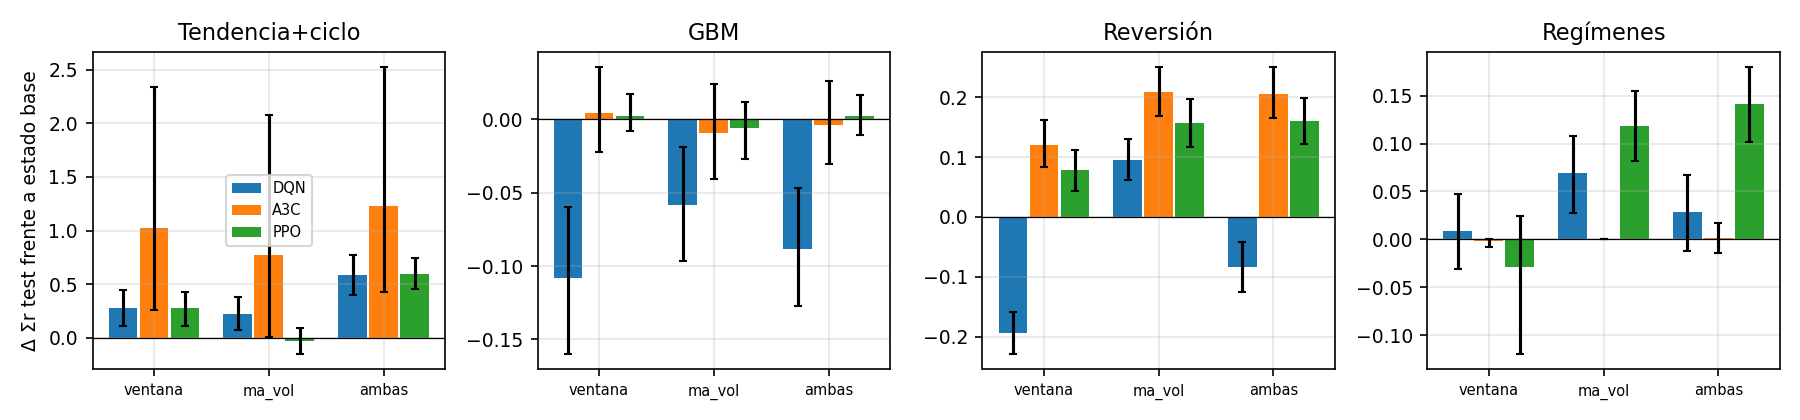

,gen,variante,n,sum_reward,sum_reward_sd,trades,best_val,best_episode,vs_base_diff,vs_base_p,vs_base_ci_low,vs_base_ci_high,vs_base_win
0,reversion,base 400 ep,3,0.279,0.009,27.123,0.328,270.000,NaN,NaN,NaN,NaN,NaN
1,reversion,ventana 400 ep,3,0.080,0.013,105.673,0.146,326.667,-0.199,0.0,-0.239,-0.158,10.0
2,reversion,"ventana 1200 ep, ε 0.99",3,0.127,0.018,101.873,0.168,620.000,-0.152,0.0,-0.196,-0.107,18.0
3,gbm,base 400 ep,3,0.013,0.001,1.013,0.122,176.667,NaN,NaN,NaN,NaN,NaN
4,gbm,ventana 400 ep,3,-0.109,0.037,115.777,0.002,146.667,-0.122,0.0,-0.184,-0.069,24.0
5,gbm,"ventana 1200 ep, ε 0.99",3,-0.109,0.037,115.777,0.002,146.667,-0.122,0.0,-0.184,-0.069,24.0


In [15]:
feat = pd.read_csv("results/table_features.csv")
cols = ["algo", "gen", "features", "n", "sum_reward", "sum_reward_sd", "log_wealth", "trades",
        "vs_base_diff", "vs_base_ci_low", "vs_base_ci_high", "vs_base_p_holm",
        "vs_rule_diff", "vs_rule_ci_low", "vs_rule_ci_high", "vs_rule_p_holm"]
display(feat[cols].round(3))
display(Image("results/figures/features.png"))
if os.path.exists("results/table_features_long.csv"):
    display(pd.read_csv("results/table_features_long.csv").round(3))

**Resultados** (Σr test; Δ frente al mismo algoritmo con el estado base, mismas semillas, IC jerárquico y Holm
sobre toda la tabla):

| | Tendencia+ciclo | GBM | Reversión | Regímenes |
|---|---|---|---|---|
| Mejor regla, estado base (§9.1) | 8.120 | 0.006 | 0.277 | 0.016 |
| DQN base → **+ vol./MA** | 7.902 → 8.123 | 0.013 → −0.045 | 0.282 → **0.377** | 0.040 → **0.109** |
| A3C base → **+ vol./MA** | 7.340 → 8.110 | 0.003 → −0.007 | 0.222 → **0.430** | 0.000 → 0.000 |
| PPO base → **+ vol./MA** | 8.095 → 8.063 | 0.011 → 0.005 | 0.287 → **0.444** | 0.000 → **0.118** |
| DQN + ventana + vol./MA | 8.487 | −0.076 | 0.199 | 0.069 |
| A3C + ventana + vol./MA | 8.566 | −0.001 | 0.428 | 0.001 |
| **PPO + ventana + vol./MA** | **8.690** | 0.013 | **0.448** | **0.141** |

**Lectura.**
- **Volatilidad y media móvil son la mejora más importante de todo el trabajo.** En reversión, los tres
  algoritmos pasan de ≈0.28 a 0.38–0.44: un 35–60% más que la mejor regla posible con el estado base. Todos
  los IC excluyen el 0 con amplio margen, por ejemplo PPO +0.157, IC [+0.12, +0.20]. El generador revierte
  hacia un nivel fijo de 100 (κ = 0.05, vida media ≈14 pasos). P/MA30 − 1 es una estimación causal de la
  distancia a ese nivel, mucho menos ruidosa que la tendencia de 6 precios.
- **En regímenes, la volatilidad identifica el régimen.** El generador usa σ = 1% en el régimen alcista y 2.5%
  en el bajista, y cambia de régimen con probabilidad 0.02 por paso, es decir, cada ≈50 pasos. Una volatilidad
  de 20 días lo detecta. DQN pasa de 0.040 a 0.109,
  por encima del mejor resultado con el estado base (Q-learning 0.077). **PPO deja de colapsar** en "siempre
  fuera": 0.118, y 0.141 si se añade también la ventana. A3C sigue en 0.
- **En el ciclo, la ventana de rendimientos es lo que aporta.** Contiene la fase del ciclo. PPO con ventana y
  vol./MA alcanza 8.690 y A3C 8.566, frente a 8.120 de la regla.
- **PPO con ventana y vol./MA es el mejor agente de todo el trabajo** en tres de los cuatro mercados:
  - ciclo, 8.690 (+0.57 sobre la regla);
  - reversión, 0.448 (+62%);
  - regímenes, 0.141, casi el doble que el mejor agente con el estado base.
  
  En GBM se queda en B&H (1 operación). Además es muy estable entre semillas (sd ≤ 0.035).
  
  Frente a la mejor regla del estado base, las diferencias son +0.57 [+0.42, +0.72], +0.171 [+0.13, +0.21] y
  +0.126 [+0.08, +0.17] (IC jerárquico), todas con p de Holm < 0.001 (columnas `vs_rule_*` de la tabla).
- **En GBM ninguna variable ayuda, como debe ser.** PPO se queda en B&H (1 operación). DQN sobreopera: 49
  operaciones con vol./MA y 108 con la ventana.
- **DQN con la ventana de 10 rendimientos falla** en reversión (0.088 con 111 operaciones; 0.199 con
  ventana + vol./MA) y en GBM. No es
  falta de muestras: con el triple de episodios y una exploración más lenta solo llega a 0.127, con ≈100
  operaciones (tabla `table_features_long`). Con los hiperparámetros del estado base, la red Q convierte el
  ruido de las 10 entradas en cambios de acción frecuentes. A3C y PPO, con la misma entrada, no lo hacen.
  Haría falta un ajuste específico (regularización, red más pequeña), que no hemos hecho. Lo dejamos
  reportado como limitación.
- **Aquí es donde la red supera a la tabla.** Con 4–14 variables continuas, la discretización de Q-learning
  es inviable: con 16 bins por variable serían entre 16⁴ y 16¹⁴ estados. Es la ventaja que el profesor
  esperaba de DQN y que con un estado de una sola variable no podía aparecer (§7).

### 9.3 Un único agente para los cuatro mercados

**Teoría.** La §8.2 mostró que las políticas son específicas del generador: un agente de momentum
aplicado a reversión pierde. Un agente generalista debe **inferir el régimen** a partir de la observación,
y con (z, posición) eso es imposible: la misma tendencia significa "compra" en el ciclo y "vende" en reversión.
Entrenamos un DQN alternando los cuatro generadores (`gen="multi"`, episodio k → generador k mod 4), con
dos observaciones:
- la base, normalizada con una σ conjunta;
- `ma_vol`: la volatilidad y la distancia a la media móvil permiten distinguir los mercados.

La validación es la media, sobre los cuatro mercados, del exceso de Σr frente a B&H estandarizado. Se compara
con el DQN especializado de cada mercado.

In [16]:
display(pd.read_csv("results/table_multi.csv").round(3))

,agente,gen,n,sum_reward,sum_reward_sd,log_wealth,trades,vs_especializado_diff,vs_especializado_p,vs_especializado_ci_low,vs_especializado_ci_high,vs_especializado_win
0,multi base,ciclo,5,7.582,0.267,5.756,64.564,-0.321,0.000,-0.557,-0.076,22.0
1,multi base,gbm,5,-0.014,0.016,-0.087,18.322,-0.027,0.157,-0.066,0.007,44.0
2,multi base,reversion,5,0.197,0.085,0.120,19.884,-0.086,0.000,-0.161,-0.017,22.0
3,multi base,regimenes,5,-0.104,0.007,-0.171,13.384,-0.144,0.000,-0.197,-0.094,29.0
4,multi ma_vol,ciclo,5,7.605,0.352,5.898,88.518,-0.297,0.000,-0.605,0.005,33.0
5,multi ma_vol,gbm,5,0.015,0.018,-0.038,14.628,0.002,0.630,-0.057,0.062,54.0
6,multi ma_vol,reversion,5,0.401,0.027,0.347,18.036,0.118,0.000,0.080,0.155,77.0
7,multi ma_vol,regimenes,5,-0.055,0.041,-0.113,15.258,-0.095,0.000,-0.158,-0.036,37.0
8,DQN especializado,ciclo,5,7.902,0.062,5.887,53.054,NaN,NaN,NaN,NaN,NaN
9,DQN especializado,gbm,5,0.013,0.001,-0.086,1.008,NaN,NaN,NaN,NaN,NaN


**Resultados** (Σr test, 5 semillas; entre paréntesis, la diferencia con el DQN especializado e IC jerárquico):

| Mercado | DQN especializado (base) | DQN especializado + vol./MA (§9.2) | Multi, estado base | Multi + vol./MA |
|---|---|---|---|---|
| Tendencia+ciclo | 7.902 | 8.123 | 7.582 (−0.32 [−0.56, −0.08]) | 7.605 (−0.30 [−0.61, +0.005]) |
| GBM | 0.013 | −0.045 | −0.014 | 0.015 |
| Reversión | 0.282 | 0.377 | 0.197 (−0.09 [−0.16, −0.02]) | **0.401** (+0.12 [+0.08, +0.16]) |
| Regímenes | 0.040 | 0.109 | −0.104 (−0.14 [−0.20, −0.09]) | −0.055 (−0.10 [−0.16, −0.04]) |

**Lectura.**
- **Con el estado base, un único agente es peor en todos los mercados con señal.** Es lo que predice la
  teoría: con (z, posición) el problema conjunto es un POMDP en el que la misma observación exige acciones
  opuestas. En regímenes cae a −0.104, casi como B&H (−0.110). Termina comprando con tendencia positiva
  porque en dos de los cuatro mercados de entrenamiento eso es lo correcto.
- **Con volatilidad y media móvil, el agente único iguala o mejora al especializado en reversión y GBM**:
  - en reversión: 0.401, frente a 0.377 del especializado con las mismas variables;
  - en GBM: 0.015 y 15 operaciones, frente a 49 del especializado con vol./MA. Ver otros mercados le
    enseña a no operar donde no hay señal.
- **Pero sigue perdiendo en ciclo y regímenes.** La volatilidad de 20 días separa bien el ciclo (media ≈0.099)
  del resto, pero GBM (0.019), reversión (0.020) y regímenes (0.017) tienen volatilidades medias casi
  iguales: con estas dos variables los regímenes son difíciles de distinguir de los otros dos.
- En el ciclo, que sí se identifica, la pérdida (−0.30, con un IC que roza el 0) es coherente con haber
  visto solo 400 episodios de ese mercado. En regímenes, la señal de la banda, ya débil, recibe también
  muchas menos muestras que en el agente especializado. Son explicaciones plausibles, no contrastadas aparte.
- La generalización requiere **identificar el mercado**: un agente único es viable solo si la observación
  contiene la información necesaria. Es la misma conclusión de §9.2, vista desde otro ángulo.

### 9.4 Comisión y zona de no operar

**Teoría.** En los modelos de cartera con costes de transacción proporcionales (Constantinides, 1986;
Davis y Norman, 1990), la política óptima tiene una **zona de no operar** que se ensancha al crecer el
coste: solo compensa operar cuando la señal supera la comisión de entrada y salida. Aquí la predicción es
directa:
- al aumentar la comisión, el agente debe operar menos;
- la distancia entre sus umbrales de compra y de venta, medida en el mapa de política, debe crecer;
- con comisión nula, la histéresis debe desaparecer.

DQN se entrena con comisiones de 0, 0.05, 0.1 (enunciado) y 0.5% (3 mercados con señal, 3 semillas). El
entorno `CostTradingEnv` es una copia del original con la comisión como parámetro; con 0.1% reproduce el
original exactamente (test). Las reglas óptimas se re-ajustan para cada comisión.

,gen,cost_pct,dqn_sum_reward,dqn_sum_reward_sd,dqn_log_wealth,dqn_trades,dqn_width,rule,rule_sum_reward,rule_trades,rule_width,dqn_vs_rule_diff,dqn_vs_rule_p,dqn_vs_rule_ci_low,dqn_vs_rule_ci_high,dqn_vs_rule_win
0,ciclo,0.00,7.929,0.053,5.919,58.333,0.383,mom_h,8.158,38.37,1.00,-0.229,0.001,-0.384,-0.079,34.0
1,ciclo,0.05,7.956,0.063,5.971,56.843,0.383,mom_h,8.139,38.37,1.00,-0.183,0.010,-0.339,-0.034,35.0
2,ciclo,0.10,7.902,0.062,5.887,53.054,0.460,mom_h,8.120,38.37,1.00,-0.218,0.002,-0.363,-0.074,35.0
3,ciclo,0.50,7.926,0.141,6.023,38.537,1.000,mom_h,7.966,38.37,1.00,-0.040,0.247,-0.199,0.096,44.0
4,reversion,0.00,0.283,0.030,0.223,57.263,1.967,con_h,0.301,23.75,2.75,-0.018,0.339,-0.067,0.025,48.0
5,reversion,0.05,0.258,0.031,0.199,32.947,2.833,con_h,0.289,23.75,2.75,-0.031,0.012,-0.073,0.005,42.0
6,reversion,0.10,0.282,0.015,0.235,24.798,3.020,con_h,0.277,23.75,2.75,0.005,0.427,-0.020,0.032,50.0
7,reversion,0.50,0.217,0.044,0.157,7.070,4.217,con_h,0.249,13.58,3.50,-0.032,0.055,-0.081,0.018,44.0
8,regimenes,0.00,0.081,0.018,0.048,30.297,2.633,band_h,0.117,54.29,2.00,-0.036,0.051,-0.081,0.006,42.0
9,regimenes,0.05,0.075,0.015,0.035,45.403,2.250,band_h,0.090,54.29,2.00,-0.015,0.296,-0.048,0.017,42.0


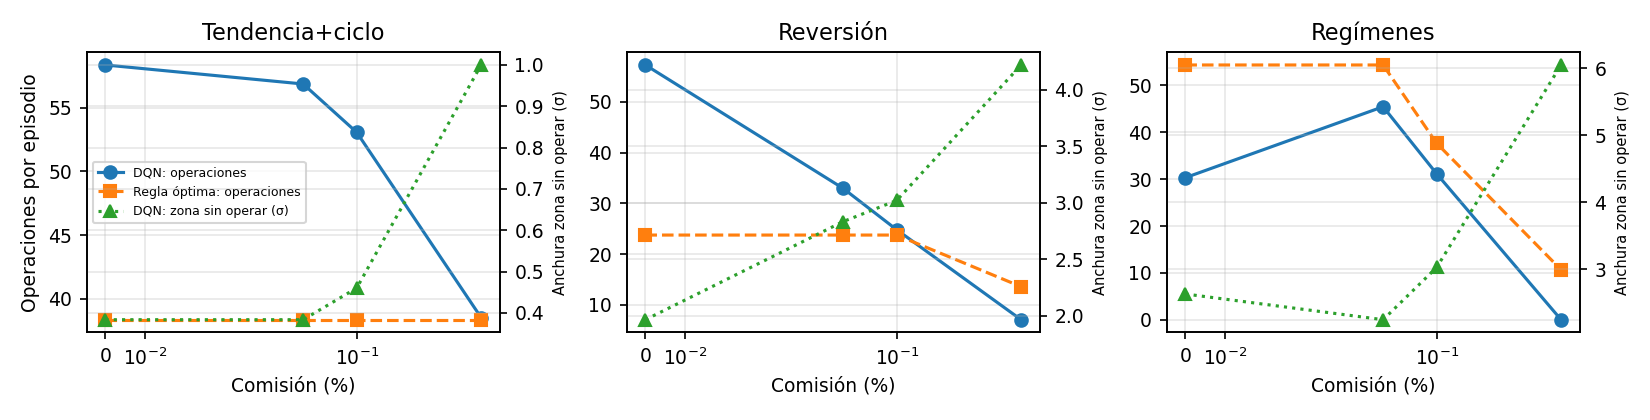

In [17]:
display(pd.read_csv("results/table_cost.csv").round(3))
display(Image("results/figures/cost.png"))

**Resultados** (DQN, 3 semillas; con 0.1%, las 5 semillas de §7; la anchura de la zona de no operar se mide
en el mapa de política, en unidades de σ de la tendencia):

| Mercado | Comisión | 0% | 0.05% | 0.1% | 0.5% |
|---|---|---|---|---|---|
| Ciclo | operaciones DQN (regla) | 58 (38) | 57 (38) | 53 (38) | 39 (38) |
| | zona sin operar DQN (regla) | 0.38σ (1.0σ) | 0.38σ (1.0σ) | 0.46σ (1.0σ) | 1.0σ (1.0σ) |
| Reversión | operaciones DQN (regla) | 57 (24) | 33 (24) | 25 (24) | 7 (14) |
| | zona sin operar DQN (regla) | 2.0σ (2.75σ) | 2.8σ (2.75σ) | 3.0σ (2.75σ) | 4.2σ (3.5σ) |
| Regímenes | operaciones DQN (regla) | 30 (54) | 45 (54) | 31 (38) | 0 (11) |
| | Σr DQN − regla [IC] | −0.04 [−0.08, +0.01] | −0.02 | +0.02 | **+0.10 [+0.04, +0.16]** |

**Lectura.**
- **El agente opera menos y ensancha la zona de no operar al subir la comisión**, como predice la teoría.
  - En reversión: de 57 a 7 operaciones, y la zona pasa de 2.0σ a 4.2σ.
  - En el ciclo: de 58 a 39 operaciones, y la zona pasa de 0.38σ a 1.0σ. Con 0.5%, DQN se comporta como la regla
    óptima: la misma anchura de zona, 39 frente a 38 operaciones y Σr indistinguible (−0.04, IC [−0.20, +0.10]).
  - Lo aprende solo a partir de la recompensa, sin saber que existe una comisión.
- **La regla óptima apenas cambia en el ciclo** (los mismos umbrales para todas las comisiones): la señal es
  tan fuerte (±20–45‰ por paso) que la comisión es despreciable frente a ella.
- **Predicción refutada: sin comisión, la histéresis no desaparece.** Ni DQN (0.38σ en ciclo, 2.0σ en reversión)
  ni la regla óptima (1.0σ y 2.75σ) colapsan a un solo umbral con comisión 0. La razón es que la observación
  no es markoviana:
  - la tendencia de 6 precios no contiene el *nivel* del precio;
  - en reversión, haber comprado tras una caída fuerte indica que el precio sigue probablemente por debajo
    del nivel de equilibrio, aunque la tendencia ya sea positiva.
  
  **La posición actúa como memoria.** La histéresis no se debe solo a la comisión, también a la observabilidad
  parcial.
- **Con comisión alta en regímenes**, DQN aprende "siempre fuera" (Σr 0.000, 0 operaciones), mientras que la
  regla re-ajustada sobreajusta y pierde (−0.103). El agente es significativamente mejor: +0.10, IC
  [+0.04, +0.16].
- **Sin comisión, DQN opera bastante más que la regla** (57 frente a 24 operaciones en reversión) con un Σr
  parecido. Sin coste que lo frene, el ruido en Q se traduce en operaciones.

### 9.5 Recompensa sensible al riesgo

**Teoría.** El agente del enunciado maximiza Σr, la suma de rendimientos **aritméticos**, que no equivale a
maximizar la riqueza: log W<sub>T</sub> = Σ log(1 + ρ<sub>t</sub>) ≈ Σρ<sub>t</sub> − ½Σρ<sub>t</sub>² −
costes. Se prueban dos recompensas alternativas, cambiando solo la recompensa que ve el agente; la evaluación
sigue siendo la misma:
- `log`: r<sub>t</sub> = log(B<sub>t</sub>/B<sub>t−1</sub>). Maximizar su suma es maximizar la log-riqueza
  final, el criterio de Kelly (1956), que penaliza implícitamente la varianza.
- `mv`: r<sub>t</sub> − λ r<sub>t</sub>², una penalización media-varianza por paso (Markowitz, 1952), con
  λ ∈ {2, 10}.

Con rendimientos diarios del 1–2%, λ = 2 apenas cambia la recompensa. Con λ = 10 el término de penalización
es del orden de la señal en reversión y regímenes. Se espera menos exposición y menos *drawdown* a cambio
de algo de rendimiento: una **frontera** riesgo-rendimiento.

,gen,modo,n,sum_reward,log_wealth,sharpe,max_dd,trades,exposure,ret_median,lw_vs_pct_diff,lw_vs_pct_p,lw_vs_pct_ci_low,lw_vs_pct_ci_high,lw_vs_pct_win
0,ciclo,pct,3,7.889,5.878,2.813,70.622,55.447,71.972,29404.003,NaN,NaN,NaN,NaN,NaN
1,ciclo,log,3,7.920,5.933,2.841,70.222,52.463,71.101,31192.542,0.054,0.008,-0.059,0.179,60.0
2,ciclo,mv2,3,7.993,6.046,2.899,68.809,47.710,69.574,35668.834,0.168,0.000,0.002,0.379,70.0
3,ciclo,mv10,3,0.405,0.355,0.760,10.902,16.367,1.697,44.992,-5.524,0.000,-5.930,-5.138,0.0
4,gbm,pct,3,0.013,-0.086,0.020,40.753,1.013,99.660,-0.107,NaN,NaN,NaN,NaN,NaN
5,gbm,log,3,-0.001,-0.084,-0.008,37.838,6.427,83.951,-2.179,0.001,0.799,-0.033,0.030,52.0
6,gbm,mv2,3,0.011,-0.087,0.018,40.631,1.000,98.721,-2.463,-0.001,0.997,-0.011,0.007,51.0
7,gbm,mv10,3,0.012,-0.085,0.018,40.499,1.000,97.965,-0.922,0.000,0.598,-0.010,0.009,54.0
8,reversion,pct,3,0.279,0.233,0.669,18.872,27.123,42.273,24.709,NaN,NaN,NaN,NaN,NaN
9,reversion,log,3,0.303,0.249,0.669,19.638,22.607,50.225,27.464,0.017,0.060,-0.012,0.045,59.0


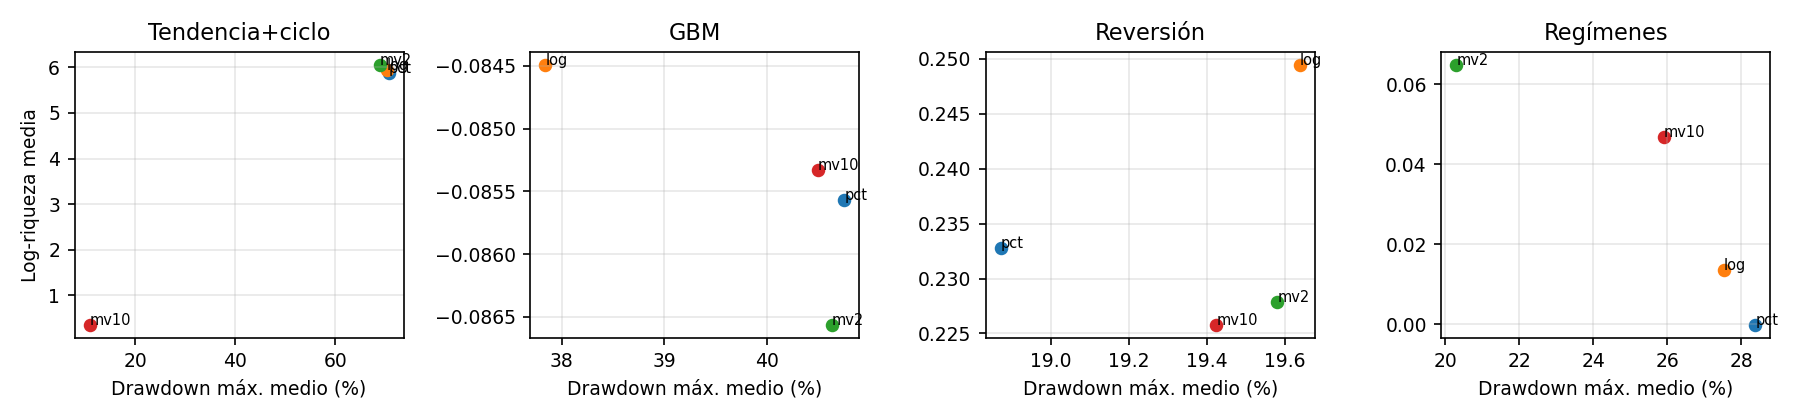

In [18]:
display(pd.read_csv("results/table_risk.csv").round(3))
display(Image("results/figures/risk_frontier.png"))

**Resultados** (DQN, semillas 10–12; la referencia `pct` es la recompensa original con esas mismas 3 semillas;
Δ log-riqueza frente a `pct` con IC jerárquico):

| Mercado | Recompensa | Σr | log-riqueza (Δ, IC) | *drawdown* máx. | exposición | operaciones |
|---|---|---|---|---|---|---|
| Ciclo | original | 7.889 | 5.878 | 70.6% | 72% | 55 |
| | log | 7.920 | +0.05 [−0.06, +0.18] | 70.2% | 71% | 52 |
| | λ = 2 | 7.993 | **+0.17 [+0.002, +0.38]** | 68.8% | 70% | 48 |
| | λ = 10 | 0.405 | −5.52 [−5.93, −5.14] | **10.9%** | 2% | 16 |
| Reversión | original | 0.279 | 0.233 | 18.9% | 42% | 27 |
| | log / λ = 2 / λ = 10 | 0.303 / 0.279 / 0.276 | todos los IC contienen el 0 | 19.4–19.6% | 47–50% | 23 |
| Regímenes | original | 0.039 | −0.000 | 28.4% | 63% | 25 |
| | log | 0.051 | +0.01 [−0.03, +0.05] | 27.5% | 60% | 34 |
| | λ = 2 | **0.088** | **+0.065 [+0.010, +0.115]** | **20.3%** | 44% | 16 |
| | λ = 10 | 0.083 | +0.047 [+0.001, +0.093] | 25.9% | 60% | 35 |
| GBM | las cuatro | 0.013 / −0.001 / 0.011 / 0.012 | todos los IC contienen el 0 | 38–41% | 84–100% | 1–6 |

**Lectura.**
- **La recompensa logarítmica no cambia nada significativo.** Era previsible: log(1 + ρ) ≈ ρ − ρ²/2, y con
  rendimientos de 1–2% por paso la corrección es diminuta. Incluso en el ciclo (≈10% por paso) solo
  equivale a λ = 0.5.
- **En regímenes, λ = 2 funciona como un filtro de régimen.** Con los parámetros del generador, la recompensa
  esperada por paso estando dentro pasa de +0.10% a +0.08% en el régimen alcista (σ = 1%), pero de −0.15% a
  −0.28% en el bajista (σ = 2.5%). La penalización castiga casi solo el régimen malo. El agente reduce la
  exposición del 63% al 44% y el *drawdown* del 28% al 20%, y **mejora incluso la Σr original** (0.039 →
  0.088, sharpe 0.10 → 0.30). Es el mismo mecanismo que la volatilidad de §9.2, pero aplicado en la
  recompensa en vez de en la observación.
- **Con λ = 10 en regímenes**, la recompensa esperada del régimen alcista es ≈0 (0.1% − 10·(1%)²). El agente
  pierde el motivo para estar dentro, opera más (35) y el *drawdown* vuelve al 26%, aunque la log-riqueza
  sigue por encima del original.
- **En el ciclo, λ = 2 mejora algo la log-riqueza (+0.17, IC justo por encima de 0) con menos operaciones.
  λ = 10 saca al agente del mercado.** Con una volatilidad ≈10% por paso, la penalización 10·ρ² ≈ 10% supera la
  señal (2–4.5% por paso). El *drawdown* baja del 71% al 11%, pero se pierde casi todo el rendimiento: es el
  extremo de la frontera.
- **En reversión y GBM no cambia nada**: las tres recompensas dan la misma política dentro del ruido.
- **λ no es transferible entre mercados**: el mismo valor no hace nada en reversión y anula el ciclo. Lo
  razonable sería fijar λσ² por mercado (§9.8).

### 9.6 PPO y Dueling DQN

**PPO** (Schulman et al., 2017) es el sucesor práctico de A3C. Usa el mismo actor-crítico de dos cabezas,
pero cambia cómo se aprovechan los datos:
- **Experiencia síncrona** de N = 16 episodios en paralelo. Para ello se usa un entorno **vectorizado**
  (`VecTradingEnv`) que replica la dinámica del original y está verificado idéntico en los tests.
- **Ventaja GAE(λ)** (Schulman et al., 2016), que interpola entre el TD(0) del crítico y Monte Carlo.
- **Objetivo recortado**: L = E[min(ρÂ, clip(ρ, 1−ε, 1+ε)Â)], con ρ = π<sub>θ</sub>/π<sub>θ_old</sub>. Permite
  varias épocas de minibatch sobre el mismo lote sin que la política se aleje demasiado de la que generó los
  datos, una región de confianza aproximada.

Se ajustó con la misma búsqueda aleatoria (12 configuraciones de α, γ y entropía, 1600 episodios, validación)
y se re-entrenó con 5 semillas y 2400 episodios.

**Dueling DQN** (Wang et al., 2016) descompone Q(s, a) = V(s) + A(s, a) − media<sub>a</sub> A(s, a). Cuando
muchas acciones tienen un valor parecido, como aquí, donde mantener o vender sin posición son equivalentes,
V se aprende con todas las transiciones.

,gen,agente,n,sum_reward,sum_reward_sd,log_wealth,trades,train_time,best_episode,vs_dqn_diff,vs_dqn_p,vs_dqn_ci_low,vs_dqn_ci_high,vs_dqn_win
0,ciclo,Q-learning,5,7.989,0.157,6.057,37.638,89.424,1090.000,0.086,0.202,-0.088,0.267,57.0
1,ciclo,DQN (Double),5,7.902,0.062,5.887,53.054,533.736,248.000,NaN,NaN,NaN,NaN,NaN
2,ciclo,Dueling DQN,5,7.874,0.057,5.875,58.238,2501.408,154.000,-0.028,0.297,-0.112,0.052,48.0
3,ciclo,A3C,5,7.638,0.910,5.593,29.950,122.117,408.000,-0.264,0.000,-1.116,0.245,33.0
4,ciclo,PPO,5,8.079,0.027,6.287,37.922,66.859,1452.800,0.177,0.008,0.039,0.317,60.0
5,ciclo,PPO 4800 ep,3,8.131,0.039,6.319,34.610,349.533,3765.333,0.229,0.002,0.078,0.380,64.0
6,gbm,Q-learning,5,-0.043,0.033,-0.104,47.324,96.996,100.000,-0.056,0.004,-0.102,-0.003,39.0
7,gbm,DQN (Double),5,0.013,0.001,-0.086,1.008,530.169,136.000,NaN,NaN,NaN,NaN,NaN
8,gbm,Dueling DQN,5,0.007,0.020,-0.088,7.520,2476.902,200.000,-0.006,0.081,-0.028,0.007,42.0
9,gbm,A3C,5,-0.006,0.032,-0.096,17.894,150.557,176.000,-0.019,0.035,-0.056,0.003,41.0


,gen,variante,n,sum_reward,sum_reward_sd,trades,exposure_test,expo_train_first10,expo_train_last10,best_val,best_episode
0,regimenes,"γ ajustado, entropía 0.0",3,0.000,0.000,0.000,0.000,40.466,0.003,0.000,32.000
1,regimenes,"γ ajustado, entropía 0.05",3,-0.000,0.000,0.013,0.003,40.694,39.593,0.001,74.667
2,regimenes,"γ ajustado, entropía 0.2",3,-0.010,0.017,15.610,25.605,47.799,47.079,0.007,640.000
3,ciclo,"γ ajustado, entropía 0.0",2,8.084,0.008,38.910,64.075,65.625,65.640,8.482,912.000
4,regimenes,"γ 0.5, entropía 0.05",3,0.000,0.000,0.000,0.000,41.551,23.651,0.000,42.667
5,regimenes,"γ 0.5, entropía 0.05, lote ×4, 9600 ep",3,0.000,0.000,0.000,0.000,44.337,26.040,0.000,128.000


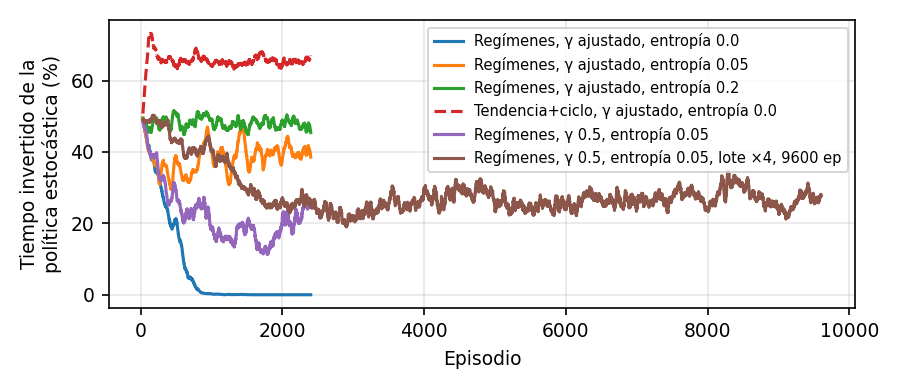

,gen,eps_min,objetivo,n,sum_reward,sum_reward_sd,trades,exposure,best_val,vs_q_diff,vs_q_p,vs_q_ci_low,vs_q_ci_high,vs_q_win
0,regimenes,0.02,Q-learning,3,0.078,0.005,28.267,48.352,0.108,NaN,NaN,NaN,NaN,NaN
1,regimenes,0.02,Expected SARSA,3,0.001,0.002,19.093,14.372,0.015,-0.076,0.000,-0.117,-0.037,32.0
2,regimenes,0.10,Q-learning,3,0.066,0.020,32.167,53.788,0.128,NaN,NaN,NaN,NaN,NaN
3,regimenes,0.10,Expected SARSA,3,0.001,0.002,19.093,14.372,0.015,-0.064,0.002,-0.111,-0.017,39.0
4,regimenes,0.30,Q-learning,3,0.059,0.016,33.577,50.706,0.128,NaN,NaN,NaN,NaN,NaN
5,regimenes,0.30,Expected SARSA,3,0.041,0.027,49.873,46.084,0.082,-0.017,0.231,-0.061,0.025,47.0
6,ciclo,0.10,Q-learning,2,8.028,0.180,38.040,69.702,8.505,NaN,NaN,NaN,NaN,NaN
7,ciclo,0.10,Expected SARSA,2,8.028,0.180,38.040,69.702,8.505,0.000,1.000,-0.280,0.252,0.0


In [19]:
algos = pd.read_csv("results/table_algos.csv")
display(algos.round(3))
if os.path.exists("results/table_ppo_explore.csv"):
    display(pd.read_csv("results/table_ppo_explore.csv").round(3))
    display(Image("results/figures/ppo_explore.png"))
if os.path.exists("results/table_onpolicy.csv"):
    display(pd.read_csv("results/table_onpolicy.csv").round(3))

**PPO frente a los algoritmos del enunciado** (Σr test, 5 semillas, Δ frente a DQN con IC jerárquico):
- **Ciclo**: 8.079 ± 0.027, el mejor agente con el estado base. Supera a DQN por +0.18, IC [+0.04, +0.32], y es
  con diferencia el más estable entre semillas (sd 0.027, frente a 0.062 de DQN y 0.91 de A3C). Con 4800
  episodios llega a 8.131 (3 semillas, +0.23 frente a DQN, IC [+0.08, +0.38]): iguala a la mejor regla.
- **Reversión**: 0.289, sin diferencia demostrada con DQN (+0.007, IC [−0.02, +0.04]; no concluyente en §11), con
  menos operaciones (17 frente a 25).
- **GBM**: 0.005, prácticamente B&H (0.9 operaciones de media).
- **Regímenes**: "siempre fuera" en las 5 semillas, igual que A3C. En el ajuste, ninguna de las 12 configuraciones
  supera 0 en validación: 8 convergen a "siempre fuera" y 4 operan y pierden.
- **Coste**: ≈70 s por entrenamiento en el ciclo, frente a ≈530 s de DQN y ≈120 s de A3C, todos medidos con la
  máquina cargada. El entorno vectorizado juega 16 episodios a la vez y cada lote se reutiliza 4 épocas.

**Dueling DQN** (Wang et al., 2016; 5 semillas, mismos hiperparámetros que DQN): **ninguna diferencia
demostrada con DQN** (en §11: equivalente en un mercado, no concluyente en los demás):
- ciclo 7.874 (−0.03, IC [−0.11, +0.05]);
- GBM 0.007 (−0.006, IC [−0.03, +0.01]), aunque opera más (7.5 frente a 1 operación);
- reversión 0.294 (+0.012, IC [−0.01, +0.04], p = 0.06);
- regímenes 0.049 (+0.009, IC [−0.02, +0.04]), con menos operaciones (20 frente a 31).

La ventaja teórica existe, pero su tamaño crece con el número de acciones: en Atari, donde Wang et al. la
midieron, hay hasta 18; aquí hay 3. Además, los hiperparámetros se
ajustaron para DQN. Los tiempos de Dueling (≈2500 s)
se midieron con la máquina saturada y no se pueden comparar con los de DQN.

**¿Por qué fallan los métodos de gradiente de política en regímenes?** Lo hemos investigado con cuatro hipótesis,
cada una con su experimento:

1. **Colapso de exploración.** Sin bonus de entropía, la política estocástica de PPO pasa de estar invertida el
   40% del tiempo (primer 10% del entrenamiento) al 0.003% (último 10%, figura). Una vez "siempre fuera", ya no
   genera datos sobre lo que pasa al comprar.
   - Pero con entropía 0.05 o 0.2 sigue explorando (40% y 47% del tiempo invertida al final) y la política
     greedy **tampoco** aprende la banda: Σr 0.000 y −0.010.
   - En el ciclo, el mismo experimento mantiene la exposición en el 65%.
   - El colapso es un **síntoma**, no la causa.
2. **Varianza de la ventaja.** El γ elegido (0.99) acumula mucho ruido en la ventaja. Con γ = 0.5 y entropía 0.05,
   y con lotes 4 veces mayores (64 entornos, 9600 episodios), el resultado sigue siendo 0.000. Menos varianza no
   basta.
3. **On-policy frente a off-policy.** Q-learning estima Q\*: el valor de comprar suponiendo que *después* se
   actuará de forma óptima (mantener en la banda y vender al salir de ella). Los métodos on-policy (A3C, PPO,
   SARSA) valoran comprar bajo **su propia política exploratoria**, que después vende o recompra al azar y paga
   comisión cada vez. Si la ventaja de estar dentro (≈0.3‰ por paso) es menor que el coste esperado de esa
   exploración, comprar parece malo y la política aprende "siempre fuera". Es el mismo fenómeno del *cliff
   walking* de Sutton y Barto (2018, ej. 6.6), donde SARSA elige el camino seguro.
   
   **Experimento**: la misma tabla, el mismo flujo de números aleatorios y los mismos hiperparámetros de
   Q-learning, cambiando solo el objetivo por Expected SARSA (van Seijen et al., 2009), es decir,
   E<sub>a'∼ε-greedy</sub>Q(s', a') en lugar de max<sub>a'</sub>Q(s', a'). Con ε final 0.02, Expected SARSA
   obtiene 0.001 frente a 0.078 de Q-learning (−0.076, IC [−0.12, −0.04], 3 semillas). En el ciclo, con señal
   fuerte, ambos llegan a la **misma** política greedy (8.028, 2 semillas). Con ε = 0.3 la diferencia es menor y no concluyente
   (0.041 frente a 0.059). Las curvas de validación explican por qué:
   - Con ε final 0.02, la política greedy de Expected SARSA queda fija en "siempre fuera": 67–70 de las 80
     evaluaciones dan exactamente 0, frente a 6–14 de Q-learning. Con ε final 0.1 el resultado es idéntico,
     porque ε = 0.995<sup>episodio</sup> no baja de 0.1 hasta el episodio ≈460 y para entonces ya ha colapsado.
   - Con ε = 0.3 sigue cayendo en "siempre fuera" mucho más que Q-learning (29–39 evaluaciones a 0, frente a
     9–11), pero la exploración persistente le hace salir a ratos, y la parada temprana elige uno de esos
     *checkpoints*.
   
   La hipótesis explica el colapso; que con más exploración se recupere en parte es un efecto de la selección
   por validación, no una refutación.
4. **Observación.** Con volatilidad y media móvil (§9.2), PPO sí aprende en regímenes (0.118). Cuando la
   observación hace la señal suficientemente grande frente al coste de explorar, el método on-policy funciona.

**Conclusión.** El fallo de A3C y PPO en regímenes no es un error de implementación: los mismos algoritmos
funcionan en los otros tres mercados y en regímenes con vol./MA. Es una propiedad de los métodos **on-policy**
cuando la ventaja es menor que el coste de su propia exploración. Q-learning y DQN, off-policy, no la sufren.
Es un argumento concreto para preferir métodos de valor off-policy en problemas de trading con señal débil y
costes de transacción.

### 9.7 Robustez estadística: corrección por comparaciones múltiples y variabilidad entre entrenamientos

*Esta sección documenta el primer paso (Holm dentro de la tabla de §7, sobre log-riqueza). El esquema
definitivo, con una familia confirmatoria, Benjamini-Hochberg para el resto y TOST para las equivalencias, está
en §11.*

La tabla de la sección 7 contiene 44 contrastes. Con α = 0.05 se esperarían ≈2 falsos positivos si todas
las hipótesis nulas fueran ciertas. Además, el Wilcoxon sobre la media de semillas trata los 5
entrenamientos como fijos: ignora que **otro conjunto de semillas** daría otros agentes. Por eso:
- se aplica la **corrección de Holm** (1979), que controla la probabilidad de algún falso positivo y
  rechaza siempre que lo haga Bonferroni (es al menos igual de potente);
- se calcula un IC por **bootstrap jerárquico**: se remuestrean primero las semillas de cada agente y luego
  las series, pareadas. Es el análogo de los intervalos por remuestreo de ejecuciones que recomiendan
  Agarwal et al. (2021) para RL profundo.

In [20]:
st = pd.read_csv("results/table_stats.csv")
display(st[st.vs == "Q-learning"].round(4))

,gen,agente,vs,mean_diff,ci_low,ci_high,p_wilcoxon,win_rate,hb_low,hb_high,p_holm
6,ciclo,DQN (Double),Q-learning,-0.170,-0.290,-0.052,1.050e-02,0.40,-0.422,0.069,9.470e-02
10,ciclo,A3C,Q-learning,-0.465,-0.546,-0.380,0.000e+00,0.13,-1.721,0.326,0.000e+00
17,gbm,DQN (Double),Q-learning,0.018,-0.017,0.053,3.154e-01,0.54,-0.050,0.069,1.000e+00
21,gbm,A3C,Q-learning,0.008,-0.025,0.041,6.036e-01,0.52,-0.060,0.060,1.000e+00
28,reversion,DQN (Double),Q-learning,0.002,-0.016,0.019,9.233e-01,0.49,-0.039,0.039,1.000e+00
32,reversion,A3C,Q-learning,-0.083,-0.113,-0.054,0.000e+00,0.30,-0.133,-0.038,0.000e+00
39,regimenes,DQN (Double),Q-learning,-0.051,-0.075,-0.026,1.000e-04,0.32,-0.085,-0.016,7.000e-04
43,regimenes,A3C,Q-learning,-0.053,-0.091,-0.015,2.830e-02,0.45,-0.093,-0.014,2.261e-01


**Qué cambia.**
- De los 44 contrastes, Holm cambia la conclusión en tres:
  - DQN frente a Q-learning en ciclo (abajo);
  - A3C frente al oráculo miope en ciclo: p de 0.005 a 0.051;
  - A3C frente a Q-learning en regímenes: p de 0.028 a 0.23, aunque su IC jerárquico [−0.093, −0.014] excluye el 0.
  
  Todas las conclusiones frente a aleatorio y B&H se mantienen.
- **DQN frente a Q-learning en el ciclo deja de ser significativo**:
  - Wilcoxon sin corregir, p = 0.011; con Holm, p = 0.095;
  - el IC jerárquico [−0.42, +0.07] contiene el 0.
  
  Lo que en una primera versión se describía como "Q-learning ligeramente superior en ciclo" es, con la
  estadística correcta, **no concluyente**; tampoco es un empate, porque el TOST de §11 no permite
  declarar equivalencia. Estos contrastes son sobre log-riqueza; en Σr (§9.6) la diferencia es aún menor
  (+0.09, p = 0.20).
- **En regímenes Q-learning sí es mejor que DQN**: Holm p = 0.0007 e IC jerárquico [−0.085, −0.016].
- El IC jerárquico es más ancho que el de series cuando un agente tiene semillas muy distintas. A3C en el
  ciclo frente a Q-learning tiene un IC de series de [−0.55, −0.38], pero el jerárquico es [−1.72, +0.33]:
  la semilla que colapsó a "siempre dentro" hace que **no** se pueda afirmar que un *nuevo* entrenamiento de
  A3C sea peor que uno de Q-learning, aunque los 5 entrenamientos realizados lo sean.

Esta distinción, entre "estos agentes" y "este algoritmo", es la que piden Henderson et al. (2018) y
Agarwal et al. (2021) para comparar métodos de RL profundo.

### 9.8 Lectura crítica de la ampliación

**Lo que consideramos sólido** (IC jerárquicos que excluyen el 0 con margen y el mismo efecto en varios
algoritmos o mercados):
- **Con el estado base, el techo lo pone la observación, no el algoritmo.** La mejor regla de umbrales,
  encontrada por búsqueda exhaustiva en entrenamiento, iguala o supera a los agentes en ciclo, reversión y GBM.
  En regímenes sobreajusta y Q-learning la supera (§9.1).
- **Volatilidad y media móvil mejoran a los tres algoritmos profundos en reversión, y a DQN y PPO en
  regímenes** (§9.2). Que el efecto se repita con tres algoritmos distintos descarta que sea un artefacto de un
  entrenamiento concreto.
- **La comisión reduce las operaciones y ensancha la zona de no operar de forma monótona** en los dos mercados
  con señal clara (§9.4).

**Lo que es más frágil, y por qué:**
1. **Pocas semillas en la ampliación.** A3C y PPO con variables nuevas, y DQN con comisión o recompensa de riesgo, usan 3 semillas. El
   IC jerárquico remuestrea semillas, pero con 3 la variabilidad entre entrenamientos está mal estimada y esos
   intervalos son algo optimistas.
2. **Hiperparámetros heredados.** Las variables nuevas, las comisiones y las recompensas de riesgo se entrenan
   con los hiperparámetros ajustados para el estado base. Los resultados son cotas inferiores de lo que cada
   variante podría dar. El fallo de DQN con la ventana de rendimientos (§9.2) es el caso más claro.
3. **Muchas preguntas al mismo test.** Ninguna variante ni hiperparámetro se eligió mirando el test: la selección
   se hace siempre en validación, con semillas 50 000+. Las p de esta sección corrigen dentro de cada tabla;
   el control sobre todo el trabajo (Holm confirmatorio y Benjamini-Hochberg exploratorio) está en §11, y es el
   que decide los veredictos de la memoria.
4. **λ no es comparable entre mercados.** La penalización λr² depende de la escala de los rendimientos. En el
   ciclo (volatilidad ≈10% por paso) λ = 10 hace la penalización mayor que la señal y el agente sale del
   mercado; en reversión (≈2%) apenas cambia nada. Una versión más limpia fijaría λσ² en lugar de λ.
5. **Medidas derivadas del mapa de política.** La anchura de la zona de no operar se mide sobre una rejilla de
   121 puntos de la tendencia (resolución 0.05σ) y solo tiene sentido con el estado base, donde la política
   depende de una sola variable.
6. **Mercados sintéticos.** Que la volatilidad identifique el régimen es cierto por construcción del generador
   (σ = 1% frente a 2.5%). No hemos probado nada con precios reales: las conclusiones se refieren a estos
   cuatro procesos.
7. **Tiempos de entrenamiento** medidos con la máquina cargada. Sirven para ordenar los algoritmos, no como
   cifras absolutas.

**Siguientes pasos, por orden de valor esperado:**
- ajustar hiperparámetros para cada estado enriquecido, sobre todo DQN con ventana;
- usar al menos 5 semillas en todas las filas de la ampliación;
- normalizar λ por la varianza de cada mercado;
- probar fuera de muestra con un generador distinto (por ejemplo GARCH) o con precios reales.

## 10. Conclusiones

1. **DQN y A3C redescubren la estrategia teóricamente esperada** en cada mercado: momentum en el ciclo,
   B&H en GBM, contraria en reversión y una banda no lineal en regímenes. Incluyen además la
   **histéresis** que impone la comisión (comprar exige más señal que mantener), que ninguna regla
   miope captura. Donde hay señal, baten al aleatorio y a B&H con significación estadística (Wilcoxon
   pareado, 100 series, p ≈ 0).
2. **Donde no hay señal (GBM), lo correcto es no operar**, y DQN lo aprende en las 5 semillas (B&H
   exacto). Es el resultado de "mercado eficiente": ninguna estrategia basada en el precio pasado bate a
   B&H, y las que operan pierden por comisión.
3. **DQN ≥ Q-learning en eficiencia muestral, ≈ en rendimiento final.** El estado de una dimensión hace
   que la discretización apenas pierda información, así que la tabla es un rival muy fuerte. La ventaja
   de la red es aprender en 100–240 episodios lo que la tabla tarda 300–1250 en aprender. Con el esquema
   global (§11), DQN gana en GBM, Q-learning gana en regímenes, y en ciclo y reversión el contraste es no
   concluyente con 5 semillas (no un empate).
4. **A3C es el más rápido en tiempo real y el más variable.** Con 4 workers entrena 1200 episodios en
   2–6 minutos, pero es sensible a la entropía y puede colapsar en óptimos locales ("siempre dentro" en
   una semilla del ciclo, "siempre fuera" en regímenes). Con más episodios iguala a DQN en reversión.
5. **La metodología importa tanto como el algoritmo.** Sin parada temprana con validación, el modelo
   final es peor que el mejor *checkpoint* (desaprendizaje). Sin varias semillas, el colapso de una
   ejecución de A3C habría llevado a conclusiones erróneas. Sin test pareado, las diferencias entre
   agentes en GBM parecerían reales.
6. **Recompensa ≠ dinero.** El agente maximiza la suma de rendimientos aritméticos. En GBM esto lleva a
   B&H, cuya riqueza *mediana* es < 1: el entorno no penaliza el riesgo.

**De la ampliación (§9):**

7. **Con la observación del enunciado, los agentes rozan el techo práctico.** La política óptima dentro de
   las que solo dependen de (tendencia, posición) es una regla de histéresis. Ajustada por búsqueda
   exhaustiva, en el ciclo supera a DQN (solo PPO es equivalente), en GBM y reversión no se distingue de los
   agentes, y en regímenes sobreajusta y Q-learning la supera. Nadie alcanza al oráculo con información
   oculta (§12).
8. **El cuello de botella es la observación, no el algoritmo.** Con volatilidad y distancia a la media móvil
   (y la ventana de rendimientos en el ciclo), PPO supera a la mejor regla posible del estado base en los
   tres mercados con señal: +0.57, +0.17 y +0.13, todos con p de Holm < 0.001. Aquí la red sí aventaja a la
   tabla.
9. **Con señal débil, los métodos on-policy prefieren no operar.** A3C, PPO y Expected SARSA caen en "siempre
   fuera" en regímenes; Q-learning y DQN, off-policy, aprenden la banda. Más entropía, menos varianza o más
   datos no lo arreglan. Una parte importante se explica por el objetivo on-policy: el método valora comprar
   bajo su propia política exploratoria, que paga comisiones al deshacer la posición (el *cliff walking*
   aplicado al trading). Con una observación más informativa, PPO sí aprende.
10. **La comisión y el riesgo moldean la política como predice la teoría, con un matiz.**
    - Con más comisión, el agente opera menos y ensancha la zona de no operar.
    - Pero la histéresis no desaparece sin comisión: la observación no es markoviana y la posición actúa como
      memoria.
    - Penalizar la varianza en regímenes (λ = 2) funciona como un filtro de régimen (el bajista es el volátil):
      el *drawdown* baja del 28% al 20% y mejora incluso la Σr (0.039 → 0.088). La recompensa logarítmica y
      Dueling DQN, en cambio, no cambian nada significativo.
    - En el ciclo, una penalización fuerte saca al agente del mercado: el *drawdown* baja del 71% al 11% a costa
      de casi todo el rendimiento.
11. **El rigor estadístico cambia conclusiones.** La corrección por comparaciones múltiples, el *bootstrap*
    jerárquico y el TOST convierten "Q-learning mejor que DQN en el ciclo" (y el "empate" que vino después) en
    "no concluyente con 5 semillas". También distinguen "estos 5 agentes" de "este algoritmo" (§11–§12).

**Limitaciones:**
- Datos sintéticos estacionarios; el agente único para los cuatro mercados solo funciona en parte (§9.3).
- Comisión fija y ejecución al precio anterior, sin deslizamiento.
- Búsqueda de hiperparámetros limitada (10–12 configuraciones). Las variantes de §9 reutilizan los
  hiperparámetros del estado base, con 3–5 semillas; DQN con la ventana de 10 rendimientos necesitaría su
  propio ajuste.
- La comparación con la regla óptima solo cubre el estado base: no hemos buscado reglas sobre el estado
  enriquecido (con 14 variables la búsqueda exhaustiva es inviable, que es justamente el argumento a favor del RL).

**Trabajo futuro:**
- Ajuste específico de DQN para estados de alta dimensión.
- Recompensa de diferencial de Sharpe, o penalización de varianza con λσ² fijo por mercado.
- Agente generalista con identificación explícita del régimen (por ejemplo, una red recurrente).
- Datos reales con validación *walk-forward*.

## 11. Evaluación estadística global (la que recoge la memoria)

Las tablas de §7–§9 aplican Holm dentro de cada tabla y sobre log-riqueza. Para la memoria se rehízo toda la
estadística con **un único esquema** sobre los 252 contrastes del trabajo (`python -m experiments.stats_report`,
módulo `rl_trading/stats.py`). Cuando una cifra de §7–§9 discrepa de esta sección, **manda esta sección**.

**Regla única de veredicto** (para cada contraste A − B en Σr, pareado en las 100 series de test):
- Wilcoxon de rangos con signo sobre la media de semillas por serie, e IC95% por *bootstrap* jerárquico
  (se remuestrean semillas de cada agente y series, pareadas).
- **Gana / pierde**: p ajustada < 0.05 **y** el IC95% excluye el 0.
- **Equivalente**: el IC90% jerárquico cae dentro de ±δ (TOST, dos tests unilaterales al 5%), con
  δ = max(0.02, 2% de |Σr de B&H|): 2 puntos de rendimiento acumulado, 0.12 en el ciclo.
- **No concluyente** en otro caso. "No significativo" **no** es "empate".

**Control del error.**
- Familia **confirmatoria**, fijada de antemano: los mínimos del enunciado (DQN y A3C frente a aleatorio y a
  B&H, y DQN frente a Q-learning, en cada mercado: 20 contrastes), con **Holm**.
- Familia **exploratoria**: todo lo demás (232 contrastes), con **Benjamini-Hochberg** a la vez.

**Tamaños del efecto**: correlación rango-biserial, % de series ganadas y **cociente de capital**
exp(Δ log-riqueza) con su IC (idea del primer grupo de compañeros, con nuestro *bootstrap* jerárquico).

**Test global**: Friedman sobre los rangos por serie de 11 agentes en cada mercado y diferencia crítica de
Nemenyi (Demšar, 2006), antes de mirar los pares.

,chi2,p,cd
gen,,,
ciclo,758.818,1.464e-156,1.51
gbm,165.056,2.925e-30,1.51
regimenes,270.533,2.582e-52,1.51
reversion,609.404,1.701e-124,1.51


gen,ciclo,gbm,regimenes,reversion
agente,,,,
A3C,5.18,5.38,5.10,4.54
Aleatorio,9.00,8.03,8.96,9.95
Buy & Hold,7.52,4.97,6.33,6.39
Contraria,10.88,6.50,7.64,6.07
DQN,4.03,5.04,4.28,3.33
Mejor regla,3.06,4.63,4.61,3.67
Momentum,5.33,6.98,7.40,10.32
Oráculo miope,4.32,8.59,7.77,6.41
PPO,3.05,4.86,5.10,3.33


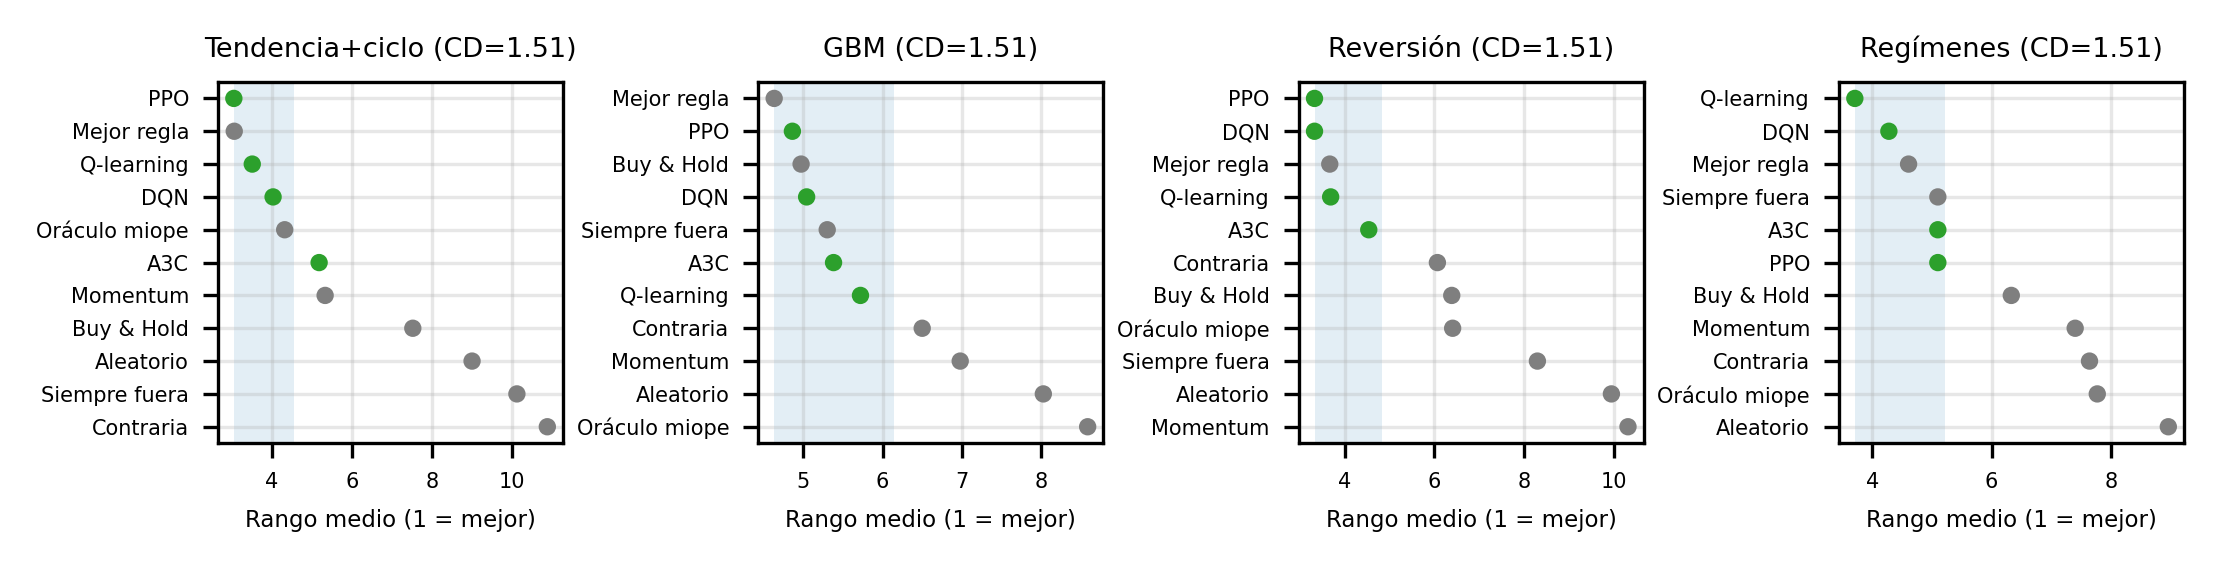

In [21]:
fr = pd.read_csv("results/table_friedman.csv")
display(fr.groupby("gen")[["chi2", "p", "cd"]].first())
display(fr.pivot(index="agente", columns="gen", values="rango_medio").round(2))
display(Image("results/figures/memo_cd.png"))

In [22]:
ac = pd.read_csv("results/table_all_contrasts.csv")
print(ac.groupby(["familia", "veredicto"]).size().unstack(fill_value=0))
display(ac[ac.familia == "confirmatoria"][["exp", "gen", "diff", "ci_low", "ci_high", "p_adj", "ci90_low", "ci90_high",
                                           "r_rb", "win", "cap_ratio", "veredicto"]].round(4))

veredicto      equivalente  gana  no concluyente  pierde
familia                                                 
confirmatoria            1    14               4       1
exploratoria            28    60             104      40


,exp,gen,diff,ci_low,ci_high,p_adj,ci90_low,ci90_high,r_rb,win,cap_ratio,veredicto
0,DQN vs Aleatorio,ciclo,5.041,4.808,5.271e+00,0.000,4.841,5.238e+00,1.000,100.0,83.931,gana
1,DQN vs Buy & Hold,ciclo,1.888,1.626,2.151e+00,0.000,1.674,2.109e+00,0.962,92.0,14.621,gana
2,A3C vs Aleatorio,ciclo,4.777,3.938,5.353e+00,0.000,4.087,5.305e+00,1.000,100.0,62.521,gana
3,A3C vs Buy & Hold,ciclo,1.624,0.803,2.221e+00,0.000,0.901,2.170e+00,0.981,96.0,10.892,gana
4,DQN vs Q-learning,ciclo,-0.086,-0.267,9.480e-02,0.606,-0.238,6.500e-02,-0.147,43.0,0.844,no concluyente
5,DQN vs Aleatorio,gbm,0.168,0.123,2.110e-01,0.000,0.131,2.049e-01,0.694,75.0,1.126,gana
6,DQN vs Buy & Hold,gbm,-0.002,-0.005,2.700e-03,0.606,-0.005,1.900e-03,-0.061,45.0,0.999,equivalente
7,A3C vs Aleatorio,gbm,0.149,0.101,1.970e-01,0.000,0.110,1.881e-01,0.706,77.0,1.115,gana
8,A3C vs Buy & Hold,gbm,-0.021,-0.057,9.000e-04,0.111,-0.050,1.000e-04,-0.263,43.0,0.989,no concluyente
9,DQN vs Q-learning,gbm,0.056,0.002,1.017e-01,0.022,0.014,9.410e-02,0.335,61.0,1.018,gana


**Potencia y tamaño muestral.** Se descompone la varianza de la diferencia en una parte entre semillas y otra
entre series, y se calcula el efecto mínimo detectable (MDE = 2.8 × error típico, α = 0.05 y potencia 80%)
para distintos números de semillas y series (idea del estudio de tamaño del test del segundo grupo, aplicada a
las diferencias entre agentes). Resumen al estilo *rliable* (Agarwal et al., 2021): media intercuartílica (IQM)
entre semillas con IC estratificado y probabilidad de mejora P(X > Y).

In [23]:
display(pd.read_csv("results/table_power.csv").round(4))
display(pd.read_csv("results/table_rliable.csv").round(4))

,gen,a,b,S,N,mde,se,seed_share,sd_seed_a,sd_seed_b,sd_series,se_bootstrap,diff,delta
0,ciclo,DQN,Q-learning,3,40,0.381,0.136,51.424,0.062,0.157,0.601,0.092,-0.086,0.12
1,ciclo,DQN,Q-learning,3,100,0.321,0.115,72.577,0.062,0.157,0.601,0.092,-0.086,0.12
2,ciclo,DQN,Q-learning,3,400,0.286,0.102,91.369,0.062,0.157,0.601,0.092,-0.086,0.12
3,ciclo,DQN,Q-learning,5,40,0.340,0.121,38.845,0.062,0.157,0.601,0.092,-0.086,0.12
4,ciclo,DQN,Q-learning,5,100,0.271,0.097,61.359,0.062,0.157,0.601,0.092,-0.086,0.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,regimenes,DQN,Buy & Hold,10,100,0.075,0.027,4.094,0.017,0.000,0.261,0.028,0.150,0.02
140,regimenes,DQN,Buy & Hold,10,400,0.040,0.014,14.584,0.017,0.000,0.261,0.028,0.150,0.02
141,regimenes,DQN,Buy & Hold,20,40,0.116,0.042,0.847,0.017,0.000,0.261,0.028,0.150,0.02
142,regimenes,DQN,Buy & Hold,20,100,0.074,0.026,2.090,0.017,0.000,0.261,0.028,0.150,0.02


,gen,agente,iqm,iqm_low,iqm_high,media,prob
0,ciclo,Q-learning,7.945,7.578,8.354,7.989,NaN
1,ciclo,DQN,7.766,7.395,8.185,7.902,NaN
2,ciclo,A3C,7.646,6.894,8.247,7.638,NaN
3,ciclo,PPO,7.979,7.604,8.389,8.079,NaN
4,ciclo,P(DQN > Q-learning),NaN,NaN,NaN,NaN,0.458
5,ciclo,P(A3C > DQN),NaN,NaN,NaN,NaN,0.468
6,ciclo,P(PPO > DQN),NaN,NaN,NaN,NaN,0.595
7,ciclo,P(PPO > A3C),NaN,NaN,NaN,NaN,0.616
8,gbm,Q-learning,-0.028,-0.112,0.026,-0.043,NaN
9,gbm,DQN,0.042,-0.070,0.149,0.013,NaN


## 12. Balance: qué batimos, qué no y qué probamos

**Oráculo con información oculta** (idea del primer grupo, recalculada con nuestras semillas): en el ciclo
conoce la media μ_t, en GBM está siempre dentro, en reversión usa una banda alrededor del nivel de equilibrio
ajustada en **entrenamiento** (no en test) y en regímenes conoce el régimen. La columna `captura` es el % del
margen entre la mejor política trivial (B&H o siempre fuera) y el oráculo que consigue cada agente.

In [24]:
display(pd.read_csv("results/table_oracle.csv").round(3))
display(pd.read_csv("results/table_verdicts.csv").round(3))

,gen,agente,sum_reward,oraculo,trivial,trivial_sr,margen,captura,band
0,ciclo,Mejor regla,8.120,11.116,Buy & Hold,6.014,5.102,41.271,NaN
1,ciclo,Q-learning,7.989,11.116,Buy & Hold,6.014,5.102,38.700,NaN
2,ciclo,DQN,7.902,11.116,Buy & Hold,6.014,5.102,37.007,NaN
3,ciclo,A3C,7.638,11.116,Buy & Hold,6.014,5.102,31.829,NaN
4,ciclo,PPO,8.079,11.116,Buy & Hold,6.014,5.102,40.475,NaN
5,ciclo,feat:dqn:ma_vol,8.123,11.116,Buy & Hold,6.014,5.102,41.337,NaN
6,ciclo,feat:ppo:ventana_ma_vol,8.690,11.116,Buy & Hold,6.014,5.102,52.446,NaN
7,gbm,Mejor regla,0.006,0.014,Buy & Hold,0.014,0.000,NaN,NaN
8,gbm,Q-learning,-0.043,0.014,Buy & Hold,0.014,0.000,NaN,NaN
9,gbm,DQN,0.013,0.014,Buy & Hold,0.014,0.000,NaN,NaN


,tabla,exp,grupo,n_x,n_y,ciclo_veredicto,ciclo_diff,ciclo_ci_low,ciclo_ci_high,ciclo_p_adj,...,reversion_p_adj,reversion_familia,reversion_exp,regimenes_veredicto,regimenes_diff,regimenes_ci_low,regimenes_ci_high,regimenes_p_adj,regimenes_familia,regimenes_exp
0,veredicto,DQN vs Aleatorio,NaN,5,1,gana,5.041,4.808,5.271,0.000,...,0.000,confirmatoria,DQN vs Aleatorio,gana,0.262,0.226,0.298,0.000,confirmatoria,DQN vs Aleatorio
1,veredicto,A3C vs Aleatorio,NaN,5,1,gana,4.777,3.938,5.353,0.000,...,0.000,confirmatoria,A3C vs Aleatorio,gana,0.222,0.184,0.263,0.000,confirmatoria,A3C vs Aleatorio
2,veredicto,DQN vs Buy & Hold,NaN,5,1,gana,1.888,1.626,2.151,0.000,...,0.000,confirmatoria,DQN vs Buy & Hold,gana,0.150,0.095,0.206,0.000,confirmatoria,DQN vs Buy & Hold
3,veredicto,A3C vs Buy & Hold,NaN,5,1,gana,1.624,0.803,2.221,0.000,...,0.000,confirmatoria,A3C vs Buy & Hold,no concluyente,0.110,0.031,0.191,0.111,confirmatoria,A3C vs Buy & Hold
4,veredicto,DQN vs Q-learning,NaN,5,5,no concluyente,-0.086,-0.267,0.095,0.606,...,0.606,confirmatoria,DQN vs Q-learning,pierde,-0.037,-0.069,-0.006,0.011,confirmatoria,DQN vs Q-learning
5,veredicto,A3C vs DQN,NaN,5,5,no concluyente,-0.264,-1.094,0.259,0.000,...,0.000,exploratoria,A3C vs DQN,no concluyente,-0.040,-0.090,0.012,0.271,exploratoria,A3C vs DQN
6,veredicto,Q-learning vs Buy & Hold,NaN,5,1,gana,1.974,1.702,2.256,0.000,...,0.000,exploratoria,Q-learning vs Buy & Hold,gana,0.187,0.124,0.250,0.000,exploratoria,Q-learning vs Buy & Hold
7,veredicto,DQN vs Mejor regla,NaN,5,1,pierde,-0.218,-0.364,-0.079,0.005,...,0.536,exploratoria,DQN vs Mejor regla,no concluyente,0.024,-0.012,0.061,0.198,exploratoria,DQN vs Mejor regla
8,veredicto,PPO vs Mejor regla,NaN,5,1,equivalente,-0.041,-0.108,0.023,0.295,...,0.447,exploratoria,PPO vs Mejor regla,no concluyente,-0.016,-0.076,0.045,0.574,exploratoria,PPO vs Mejor regla
9,veredicto,PPO+ventana+vol./MA vs Mejor regla,NaN,3,1,gana,0.570,0.418,0.727,0.000,...,0.000,exploratoria,PPO+ventana+vol./MA vs Mejor regla,gana,0.126,0.078,0.174,0.000,exploratoria,PPO+ventana+vol./MA vs Mejor regla


**Qué probamos.** Cada experimento de §8–§9 y las ideas de los compañeros (parada temprana frente al modelo
final y *ensemble* de las 5 semillas, `python -m experiments.extras_peers`), con la misma regla, agrupados en
*mejoró* (gana en algún mercado y no pierde en ninguno), *depende del mercado*, *sin cambio demostrable* y
*empeoró*.

In [25]:
display(pd.read_csv("results/table_tried.csv").round(3))

,tabla,exp,grupo,n_x,n_y,ciclo_veredicto,ciclo_diff,ciclo_ci_low,ciclo_ci_high,ciclo_p_adj,...,reversion_p_adj,reversion_familia,reversion_exp,regimenes_veredicto,regimenes_diff,regimenes_ci_low,regimenes_ci_high,regimenes_p_adj,regimenes_familia,regimenes_exp
0,probado,Quitar la red objetivo (final),sin cambio,2,2,no concluyente,-0.040,-0.169,0.080,0.351,...,0.000,exploratoria,Quitar la red objetivo (final),no concluyente,0.001,-0.045,0.039,0.899,exploratoria,Quitar la red objetivo (final)
1,probado,Double frente a solo red objetivo (final),mejoró,2,2,gana,0.105,0.013,0.203,0.000,...,0.000,exploratoria,Double frente a solo red objetivo (final),no concluyente,-0.012,-0.058,0.034,0.878,exploratoria,Double frente a solo red objetivo (final)
2,probado,Dueling DQN,sin cambio,5,5,equivalente,-0.028,-0.119,0.052,0.401,...,0.103,exploratoria,Dueling DQN,no concluyente,0.009,-0.024,0.042,0.574,exploratoria,Dueling DQN
3,probado,Último paso terminal (sin bootstrap),sin cambio,3,5,equivalente,-0.019,-0.127,0.100,0.149,...,0.500,exploratoria,Último paso terminal (sin bootstrap),no concluyente,-0.002,-0.053,0.052,0.949,exploratoria,Último paso terminal (sin bootstrap)
4,probado,γ=0.0 (frente a 0.5),sin cambio,2,2,no concluyente,-0.026,-0.185,0.166,0.631,...,0.536,exploratoria,γ=0.0 (frente a 0.5),no concluyente,-0.033,-0.103,0.046,0.271,exploratoria,γ=0.0 (frente a 0.5)
5,probado,γ=0.9 (frente a 0.5),empeoró,2,2,pierde,-0.135,-0.228,-0.040,0.003,...,0.923,exploratoria,γ=0.9 (frente a 0.5),no concluyente,-0.082,-0.162,0.003,0.011,exploratoria,γ=0.9 (frente a 0.5)
6,probado,γ=0.99 (frente a 0.5),sin cambio,2,2,no concluyente,-0.082,-0.206,0.026,0.003,...,0.396,exploratoria,γ=0.99 (frente a 0.5),no concluyente,-0.007,-0.076,0.069,0.839,exploratoria,γ=0.99 (frente a 0.5)
7,probado,Más episodios,mejoró,5,5,equivalente,0.052,-0.015,0.137,0.042,...,0.000,exploratoria,Más episodios,no concluyente,0.020,-0.016,0.055,0.160,exploratoria,Más episodios
8,probado,Parada temprana DQN,mejoró,5,5,no concluyente,-0.081,-0.173,0.008,0.000,...,0.000,exploratoria,Parada temprana DQN,gana,0.055,0.011,0.093,0.000,exploratoria,Parada temprana DQN
9,probado,Parada temprana A3C,mejoró,5,5,no concluyente,-0.056,-0.981,0.911,0.024,...,0.000,exploratoria,Parada temprana A3C,equivalente,0.000,0.000,0.000,1.000,exploratoria,Parada temprana A3C


**Último paso: terminal o límite de tiempo.** El entorno marca el último paso como `terminated`. Nuestros agentes
lo tratan como límite de tiempo (*bootstrap*). La fila "Último paso terminal (sin bootstrap)" de la tabla anterior
reentrena DQN con la configuración final y `timeout_bootstrap=False` (3 semillas por mercado,
`python -m experiments.main terminal`).

**Tiempos sin carga en los cuatro mercados** (`python -m experiments.main timing 1`, una ejecución detrás de otra):

In [26]:
import glob, json
tm = pd.DataFrame([{k: json.load(open(f))[k] for k in ("algo", "gen", "train_time")}
                   for f in glob.glob("results/timing/*_s10.json")])
display(tm.pivot(index="algo", columns="gen", values="train_time").round(1))

gen,ciclo,gbm,regimenes,reversion
algo,,,,
a3c,36.8,55.1,16.7,16.9
dqn,203.1,172.5,159.0,172.1
qlearning,46.9,24.4,25.1,23.7


In [27]:
# Cifras que cita la memoria en el balance (mismo cálculo que memoria_text.py)
def row(exp, g):
    return ac[(ac.exp == exp) & (ac.gen == g)].iloc[0]
for g in ["ciclo", "gbm", "reversion", "regimenes"]:
    x = row("DQN vs Q-learning", g)
    print(f"DQN − Q-learning, {g:10s}: Δ={x['diff']:+.3f}  IC95=[{x.ci_low:+.3f}, {x.ci_high:+.3f}]  "
          f"IC90=[{x.ci90_low:+.3f}, {x.ci90_high:+.3f}]  δ={x.delta:.2f}  p_Holm={x.p_adj:.4f}  → {x.veredicto}")
x = row("DQN vs Mejor regla", "ciclo")
print(f"DQN − mejor regla (ciclo): Δ={x['diff']:+.2f}  IC=[{x.ci_low:+.2f}, {x.ci_high:+.2f}]  → {x.veredicto}")
sp = ac[ac.exp.str.startswith("S&P")]
print(f"S&P 500: {(sp.veredicto == 'gana').sum()} de {len(sp)} ejecuciones significativas tras Benjamini-Hochberg")

DQN − Q-learning, ciclo     : Δ=-0.086  IC95=[-0.267, +0.095]  IC90=[-0.238, +0.065]  δ=0.12  p_Holm=0.6063  → no concluyente
DQN − Q-learning, gbm       : Δ=+0.056  IC95=[+0.002, +0.102]  IC90=[+0.014, +0.094]  δ=0.02  p_Holm=0.0220  → gana
DQN − Q-learning, reversion : Δ=+0.011  IC95=[-0.032, +0.052]  IC90=[-0.025, +0.045]  δ=0.02  p_Holm=0.6063  → no concluyente
DQN − Q-learning, regimenes : Δ=-0.037  IC95=[-0.069, -0.006]  IC90=[-0.064, -0.010]  δ=0.02  p_Holm=0.0112  → pierde
DQN − mejor regla (ciclo): Δ=-0.22  IC=[-0.36, -0.08]  → pierde
S&P 500: 1 de 9 ejecuciones significativas tras Benjamini-Hochberg


**Lectura** (la misma que la memoria, §3–§4):
- **Batimos** al aleatorio en los 4 mercados con DQN y A3C, y a B&H donde hay señal. En GBM, DQN es
  *equivalente* a B&H por TOST, que es lo correcto sin señal. A3C frente a B&H en regímenes no resiste a Holm.
- **DQN frente a Q-learning**: DQN gana en GBM, pierde en regímenes y es **no concluyente** en ciclo y reversión
  (no un empate: el IC90% se sale de ±δ). El 61–83% de la incertidumbre viene de las semillas: para separar
  algoritmos hacen falta más semillas, no más series. Esto corrige lo que §7.1 y §9.7 llaman "empate".
- **No batimos** a la mejor regla de umbrales en el ciclo, y nadie alcanza al oráculo oculto. Con más
  información en el estado (PPO + ventana + vol./MA) sí se bate a la regla y sube la captura del margen.
- **Ideas de los compañeros**: la parada temprana mejora a DQN frente al modelo final en reversión y
  regímenes; el *ensemble* de A3C neutraliza la semilla que colapsó en el ciclo, pero el de DQN en regímenes
  promedia bandas distintas y acaba "siempre fuera" (promediar valores no promedia políticas).

## Apéndice: reproducibilidad

```bash
python tests_sanity.py                         # simulador == entorno, B&H == notebook
python -m experiments.baselines_eval           # referencias en validación y test
python -m experiments.tune dqn,qlearning 20    # ajuste (validación)
python -m experiments.tune a3c 4
python -m experiments.main final 20            # 5 semillas x 4 mercados x 3 algoritmos
python -m experiments.main ablations 14 dqn    # variantes DQN y gamma
python -m experiments.main iteration 5 dqn     # iteraciones de mejora
python -m experiments.main iteration_a3c 5 a3c
python -m experiments.main iteration_a3c_reg 5 a3c
python -m experiments.main workers 1 a3c       # escalado A3C (máquina sin carga)
python -m experiments.main sp500 6             # S&P 500 real
python -m experiments.sp500_null               # S&P 500: contraste frente a estrategias aleatorias
python -m experiments.main timing 1            # tiempos sin carga, 4 mercados, uno detrás de otro
python -m experiments.main terminal 12 dqn     # último paso terminal (sin bootstrap) frente a límite de tiempo
python -m experiments.analysis                 # tablas y figuras
# --- ampliación (§9) ---
python -m pytest tests/test_core.py            # 38 tests (comisión variable, entorno vectorizado, causalidad, regla de veredicto, oráculo, ensemble...)
python -m experiments.rules_eval               # reglas óptimas por búsqueda exhaustiva (4 comisiones)
python -m experiments.tune ppo 8               # ajuste de PPO
python -m experiments.main final 4 ppo         # PPO, 5 semillas
python -m experiments.main ext_dqn 20 dqn      # estado enriquecido, multi-mercado, comisión, Dueling, riesgo
python -m experiments.main ext_a3c 2 a3c       # estado enriquecido en A3C
python -m experiments.main ext_ppo_feat 4 ppo  # estado enriquecido en PPO
python -m experiments.main ext_ppo 4 ppo       # PPO: entropía en regímenes y 4800 episodios
python -m experiments.main ext_ppo_snr 4 ppo   # PPO: γ corto y lotes grandes en regímenes
python -m experiments.main ext_onpolicy 6 qlearning   # Q-learning frente a Expected SARSA
python -m experiments.main ext_dqn_feat_long 6 dqn    # DQN con ventana: más episodios
python -m experiments.analysis_ext             # tablas y figuras de §9
# --- evaluación global y balance (§11-§12) ---
python -m experiments.extras_peers             # oráculo oculto, ensemble, parada temprana vs modelo final
python -m experiments.stats_report             # 252 contrastes, Friedman-Nemenyi, potencia, tablas de la memoria
python build_notebook.py; python make_memoria.py; python check_memoria.py
```
Entorno: Python 3.13, PyTorch 2.6 (CPU, 1 hilo por proceso), Gymnasium, NumPy, SciPy; AMD Ryzen 9 7945HX (16 núcleos).